<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-06/generative-models.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Generative models

*Deep Learning for Scientific Discovery, Jagiellonian University. Author: Marcin Płodzień.*

The data $\mathbf x_1,\dots,\mathbf x_n$ we collect are **samples** from an unknown probability distribution $p(\mathbf x)$: the distribution of handwritten digits, of cell images, of spin configurations of a magnet at temperature $T$. A **generative model** learns an approximation $p_\theta(\mathbf x)$ of this distribution from the samples and can then **draw new samples**, instances that were never in the data set but look as if they could have been.

The notebook builds this idea up in small experiments, each of which runs on a laptop CPU (central processing unit). It starts from the probability toolkit used throughout (discrete and continuous distributions, expectations, the Gaussian, joint, conditional and marginal distributions, and the Kullback–Leibler divergence), and with the distinction between probability and likelihood. Maximum likelihood then lets us fit a distribution to points in two dimensions and sample from it. For images such a formula is out of reach, so we turn to neural networks: we first see that an ordinary autoencoder cannot generate, and then how the variational autoencoder (VAE) repairs this and produces new digits from random latent vectors. Giving the VAE a condition lets us choose the digit, and the same conditional VAE generates blood-cell images of a chosen type. Finally, we return to the 2D Ising model, where the true distribution is known, and check a conditional VAE that generates spin configurations at a chosen temperature against Monte Carlo.

All random generators are seeded, so the numbers agree with the slides, and every section ends with an exercise.

Shared settings: the computation is restricted to the CPU with four threads, figures for the slides go to `../beamer/figures`, numbers quoted on the slides are collected in the dictionary `nums` and saved to `results/`, and `seed` fixes the random generators of PyTorch and NumPy.

In [1]:
import os, json, time
os.environ["CUDA_VISIBLE_DEVICES"] = ""
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
torch.set_num_threads(4)
import os
OUT = "figures"; os.makedirs(OUT, exist_ok=True); os.makedirs(OUT, exist_ok=True)      # figures of the slides
RES = "results"; os.makedirs(RES, exist_ok=True)
blue, orange, navy = "#005CA7", "#EB6709", "#0A2F5C"
cmap = plt.get_cmap("tab10")
nums = {}                                                        # numbers quoted on the slides
def clean(ax):
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
def seed(k):
    torch.manual_seed(k); return np.random.default_rng(k)

## Probability toolkit

The lecture is phrased in the language of probability. The objects it needs are collected here, each with a small computation: discrete and continuous distributions, expectations as averages over samples, the Gaussian, joint, conditional and marginal distributions, the Kullback–Leibler divergence, and its link to maximum likelihood.

### Discrete and continuous distributions

For a discrete variable $x$, such as the outcome of a die, a class label or a spin, $p(x)$ is a probability:
$$0\le p(x)\le 1,\qquad \sum_x p(x)=1. \tag{1}$$
For a continuous variable, such as a pixel intensity, a temperature or a coordinate, $p(x)$ is a **density**. Only areas under it are probabilities,
$$P(a\le x\le b)=\int_a^b p(x)\,dx,\qquad \int p(x)\,dx=1, \tag{2}$$
and the density itself can be larger than 1. Two numbers illustrate the difference: the probability that a standard Gaussian falls within one standard deviation of its mean, and the peak value of the narrow Gaussian $\mathcal N(0,0.2^2)$.

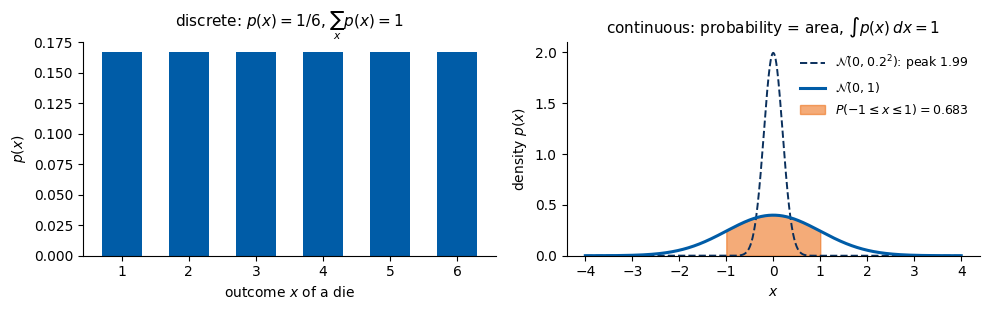

P(-1 <= x <= 1) for N(0,1): 0.683;  peak of N(0, 0.2^2): 1.99 > 1


In [2]:
from scipy.stats import norm
xs = np.linspace(-4, 4, 1601)
nums["gauss_P_within_1sigma"] = float(norm.cdf(1) - norm.cdf(-1))
nums["gauss_peak_sigma02"] = float(norm.pdf(0, 0, 0.2))
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].bar(range(1, 7), [1 / 6] * 6, color=blue, width=0.6)
axs[0].set_xlabel("outcome $x$ of a die"); axs[0].set_ylabel("$p(x)$")
axs[0].set_title(r"discrete: $p(x) = 1/6$, $\sum_x p(x) = 1$", fontsize=11)
axs[1].plot(xs, norm.pdf(xs, 0, 0.2), color=navy, lw=1.4, ls="--", label=r"$\mathcal{N}(0, 0.2^2)$: peak 1.99")
axs[1].plot(xs, norm.pdf(xs), color=blue, lw=2.2, label=r"$\mathcal{N}(0, 1)$")
m = (xs >= -1) & (xs <= 1); axs[1].fill_between(xs[m], norm.pdf(xs[m]), color=orange, alpha=0.55, label=r"$P(-1 \leq x \leq 1) = 0.683$")
axs[1].set_xlabel("$x$"); axs[1].set_ylabel("density $p(x)$"); axs[1].set_ylim(0, 2.1)
axs[1].set_title(r"continuous: probability = area, $\int p(x)\,dx = 1$", fontsize=11); axs[1].legend(frameon=False, fontsize=9)
for a in axs: clean(a)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_discrete_continuous.png", dpi=170, bbox_inches="tight"); plt.show()
print(f"P(-1 <= x <= 1) for N(0,1): {nums['gauss_P_within_1sigma']:.3f};  peak of N(0, 0.2^2): {nums['gauss_peak_sigma02']:.2f} > 1")

The area under each curve is 1, yet the narrow Gaussian reaches a peak of about 2: a density is not a probability. An image is a vector of 784 numbers, and $p(\mathbf x)$ is a density in 784 dimensions.

### Expectation and averages over samples

The **expectation** of a function $f$ under $p$ is its average weighted by the probabilities,
$$\mathbb E_{x\sim p}[f(x)]=\sum_x p(x)\,f(x)\quad\text{or}\quad\int p(x)\,f(x)\,dx . \tag{3}$$
We almost never know $p$, but we do have samples $x_1,\dots,x_n$ from it, and the expectation is approximated by the sample average,
$$\mathbb E_{x\sim p}[f(x)]\approx\frac1n\sum_{i=1}^n f(x_i), \tag{4}$$
with an error that shrinks like $1/\sqrt n$. Every loss in this lecture is such an average, computed on a mini-batch.

As an example we take a mixture of two Gaussians,
$$p(x)=\tfrac12\,\mathcal N(x;-2,0.6^2)+\tfrac12\,\mathcal N(x;1.5,1), \tag{5}$$
whose mean is exactly
$$\mathbb E[x]=\tfrac12(-2)+\tfrac12(1.5)=-0.25, \tag{6}$$
and estimate this mean from 10, 100 and 10 000 samples.

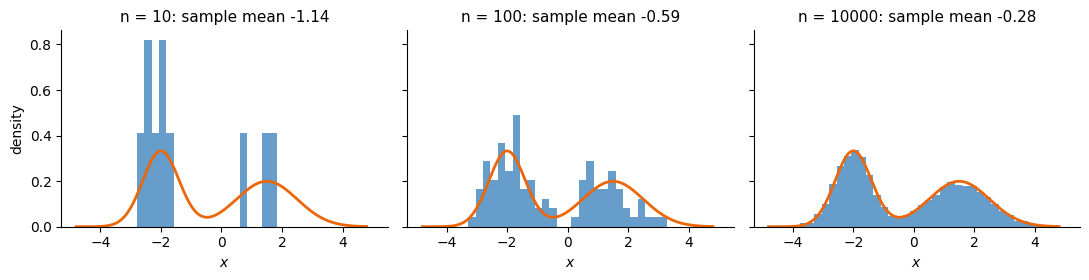

exact E[x] = -0.25; estimates from n samples: {'10': -1.142, '100': -0.591, '10000': -0.282}


In [3]:
def p_mix(x):                                               # the density of the example
    return 0.5 * norm.pdf(x, -2, 0.6) + 0.5 * norm.pdf(x, 1.5, 1.0)
def sample_mix(n, rng):
    k = rng.random(n) < 0.5
    return np.where(k, rng.normal(-2, 0.6, n), rng.normal(1.5, 1.0, n))
rng = seed(20)
fig, axs = plt.subplots(1, 3, figsize=(11, 2.9), sharey=True)
est = {}
for a, n in zip(axs, [10, 100, 10000]):
    s = sample_mix(n, rng); est[n] = float(s.mean())
    a.hist(s, bins=np.linspace(-4.5, 5, 40), density=True, color=blue, alpha=0.6)
    a.plot(xs * 1.2, p_mix(xs * 1.2), color=orange, lw=2)
    a.set_title(f"n = {n}: sample mean {s.mean():+.2f}", fontsize=11); a.set_xlabel("$x$"); clean(a)
axs[0].set_ylabel("density")
nums["mix_mean_estimates"] = {str(k): round(v, 3) for k, v in est.items()}
plt.tight_layout(); plt.savefig(f"{OUT}/gen_samples_expectation.png", dpi=170, bbox_inches="tight"); plt.show()
print("exact E[x] = -0.25; estimates from n samples:", nums["mix_mean_estimates"])

With 10 samples the histogram hardly resembles $p$ and the estimated mean, $-1.142$, is far from $-0.25$; with 10 000 samples both the histogram and the mean ($-0.282$) are close. A generative model only ever sees such samples.

### Gaussian distribution

In one dimension, with mean $\mu$ and standard deviation $\sigma$,
$$\mathcal N(x;\mu,\sigma^2)=\frac{1}{\sqrt{2\pi\sigma^2}}\exp\!\Big(-\frac{(x-\mu)^2}{2\sigma^2}\Big). \tag{7}$$
In $d$ dimensions with independent coordinates,
$$\mathcal N(\mathbf z;\boldsymbol\mu,\mathrm{diag}\,\boldsymbol\sigma^2)=\prod_{k=1}^d\mathcal N(z_k;\mu_k,\sigma_k^2), \tag{8}$$
and the **standard** Gaussian $\mathcal N(0,I)$ has all means 0 and all standard deviations 1. To draw from $\mathcal N(\boldsymbol\mu,\mathrm{diag}\,\boldsymbol\sigma^2)$ it is enough to draw $\boldsymbol\varepsilon$ from $\mathcal N(0,I)$ and compute
$$\mathbf z=\boldsymbol\mu+\boldsymbol\sigma\odot\boldsymbol\varepsilon, \tag{9}$$
where $\odot$ is the element-wise product. This shift-and-stretch reappears as the reparametrisation trick of the VAE. Applied with means $(3,1)$ and standard deviations $(0.5,1.5)$, it gives samples whose mean and standard deviation reproduce these values.

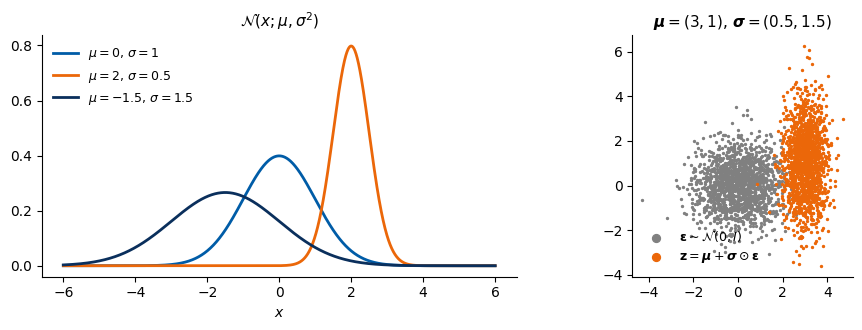

sample mean of z: [3.02 1.05]  sample std of z: [0.49 1.47]


In [4]:
rng = seed(21)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
for (mu, sg), col in zip([(0, 1), (2, 0.5), (-1.5, 1.5)], [blue, orange, navy]):
    axs[0].plot(xs * 1.5, norm.pdf(xs * 1.5, mu, sg), color=col, lw=2, label=rf"$\mu = {mu}$, $\sigma = {sg}$")
axs[0].legend(frameon=False, fontsize=9); axs[0].set_xlabel("$x$"); axs[0].set_title(r"$\mathcal{N}(x; \mu, \sigma^2)$", fontsize=11)
eps = rng.standard_normal((1500, 2)); mu2, sg2 = np.array([3.0, 1.0]), np.array([0.5, 1.5])
z = mu2 + sg2 * eps
axs[1].scatter(*eps.T, s=2, color="grey", label=r"$\boldsymbol{\varepsilon} \sim \mathcal{N}(0, I)$")
axs[1].scatter(*z.T, s=2, color=orange, label=r"$\mathbf{z} = \boldsymbol{\mu} + \boldsymbol{\sigma} \odot \boldsymbol{\varepsilon}$")
axs[1].set_aspect("equal"); axs[1].legend(frameon=False, fontsize=9, loc="lower left", markerscale=4)
axs[1].set_title(r"$\boldsymbol{\mu} = (3, 1)$, $\boldsymbol{\sigma} = (0.5, 1.5)$", fontsize=11)
for a in axs: clean(a)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_gaussian.png", dpi=170, bbox_inches="tight"); plt.show()
print("sample mean of z:", z.mean(0).round(2), " sample std of z:", z.std(0).round(2))

### Joint, conditional and marginal distributions

Consider two variables, an observed $x$ and a hidden (latent) $z$. Their **joint** distribution $p(x,z)$ gives the probability of both together, and the other distributions follow from it. The **marginal**
$$p(x)=\int p(x,z)\,dz \tag{10}$$
is the distribution of $x$ alone, whatever $z$ is. The **conditional**
$$p(x\,|\,z)=\frac{p(x,z)}{p(z)} \tag{11}$$
is the distribution of $x$ once $z$ is known, which gives the **product rule**
$$p(x,z)=p(x\,|\,z)\,p(z). \tag{12}$$
Turning the conditional around gives **Bayes' rule**,
$$p(z\,|\,x)=\frac{p(x\,|\,z)\,p(z)}{p(x)}, \tag{13}$$
which states what an observed $x$ tells us about the hidden $z$; this distribution is the **posterior**.

A latent-variable model illustrates this:
$$z\sim\mathcal N(0,1),\qquad x\,|\,z\sim\mathcal N\big(2\tanh(2z),\,0.35^2\big). \tag{14}$$
Although both ingredients are Gaussian, the marginal $p(x)$ is not. We compute the joint density on a grid, integrate out $z$ to obtain $p(x)$, and evaluate the posterior of $z$ for the observed value 1 of $x$.

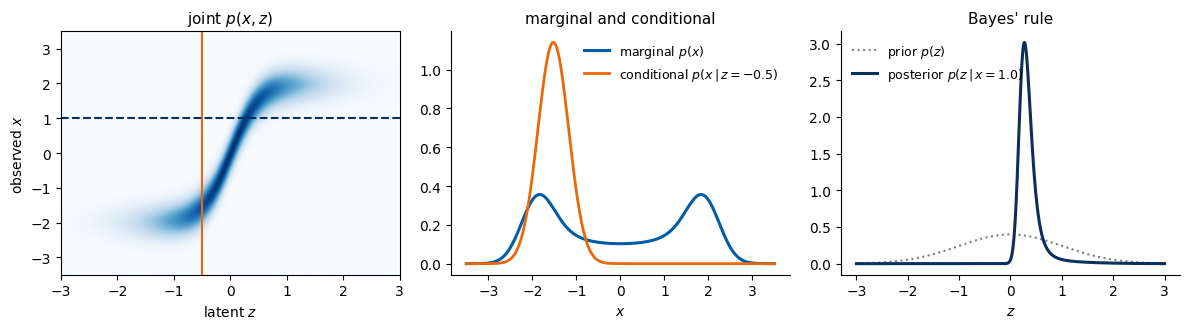

integral of p(x): 0.9973;  posterior p(z | x = 1.0): mean 0.360, std 0.245


In [5]:
zg = np.linspace(-3, 3, 601); xg = np.linspace(-3.5, 3.5, 701); dz, dx = zg[1] - zg[0], xg[1] - xg[0]
fz = lambda z: 2 * np.tanh(2 * z); s_x = 0.35
joint = norm.pdf(zg)[None, :] * norm.pdf(xg[:, None], fz(zg)[None, :], s_x)     # rows: x, columns: z
px = joint.sum(1) * dz                                                           # marginal p(x)
z0, x0 = -0.5, 1.0
post = joint[np.argmin(abs(xg - x0))] / px[np.argmin(abs(xg - x0))]                # p(z | x0), Bayes
nums["post_mean"] = float((zg * post).sum() * dz); nums["post_std"] = float(np.sqrt(((zg - nums["post_mean"]) ** 2 * post).sum() * dz))
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
axs[0].imshow(joint, origin="lower", extent=[zg[0], zg[-1], xg[0], xg[-1]], aspect="auto", cmap="Blues")
axs[0].axvline(z0, color=orange, lw=1.5); axs[0].axhline(x0, color=navy, lw=1.5, ls="--")
axs[0].set_xlabel("latent $z$"); axs[0].set_ylabel("observed $x$"); axs[0].set_title("joint $p(x, z)$", fontsize=11)
axs[1].plot(xg, px, color=blue, lw=2.2, label="marginal $p(x)$")
axs[1].plot(xg, norm.pdf(xg, fz(z0), s_x), color=orange, lw=2, label=f"conditional $p(x\\,|\\,z = {z0})$")
axs[1].set_xlabel("$x$"); axs[1].legend(frameon=False, fontsize=9); axs[1].set_title("marginal and conditional", fontsize=11)
axs[2].plot(zg, norm.pdf(zg), color="grey", lw=1.5, ls=":", label="prior $p(z)$")
axs[2].plot(zg, post, color=navy, lw=2.2, label=f"posterior $p(z\\,|\\,x = {x0})$")
axs[2].set_xlabel("$z$"); axs[2].legend(frameon=False, fontsize=9, loc="upper left"); axs[2].set_title("Bayes' rule", fontsize=11)
for a in axs[1:]: clean(a)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_joint_conditional.png", dpi=170, bbox_inches="tight"); plt.show()
print(f"integral of p(x): {px.sum() * dx:.4f};  posterior p(z | x = {x0}): mean {nums['post_mean']:.3f}, std {nums['post_std']:.3f}")

The marginal $p(x)$ has two peaks, because $\tanh$ maps most values of $z$ close to $\pm2$. Observing the value 1 narrows the possible $z$ from the broad prior (standard deviation 1) to a narrow posterior with mean 0.360 and standard deviation 0.245, close to 0.27, the value of $z$ at which the mean $2\tanh(2z)$ in equation (14) reaches 1. A VAE needs exactly this posterior, and its **encoder** learns an approximation of it.

### Kullback–Leibler divergence and maximum likelihood

To measure how far a model $q$ is from the true distribution $p$ we use the Kullback–Leibler (KL) divergence
$$\mathrm{KL}(p\,\|\,q)=\mathbb E_{x\sim p}\Big[\log\frac{p(x)}{q(x)}\Big]=\int p(x)\log\frac{p(x)}{q(x)}\,dx . \tag{15}$$
It is non-negative, zero only when $q$ and $p$ coincide, and not symmetric. It can be read as the average *extra surprise* when data from $p$ are described by $q$.

Splitting the logarithm gives
$$\mathrm{KL}(p\,\|\,p_\theta)=\mathbb E_p[\log p]-\mathbb E_p[\log p_\theta]. \tag{16}$$
The first term does not depend on $\theta$, and the second is estimated by the mean log-likelihood of the samples,
$$\mathbb E_p[\log p_\theta]\approx\frac1n\sum_{i=1}^n\log p_\theta(x_i). \tag{17}$$
Hence
$$\text{maximising the log-likelihood}\;\Longleftrightarrow\;\text{minimising }\mathrm{KL}(p\,\|\,p_\theta). \tag{18}$$
We test this by fitting one Gaussian $\mathcal N(\mu,\sigma^2)$ to the two-peak mixture of equation (5). The KL divergence should be smallest when $\mu$ is the mean of $p$, $-0.25$ by equation (6), and maximum likelihood on samples, which gives the sample mean, should land close to it.

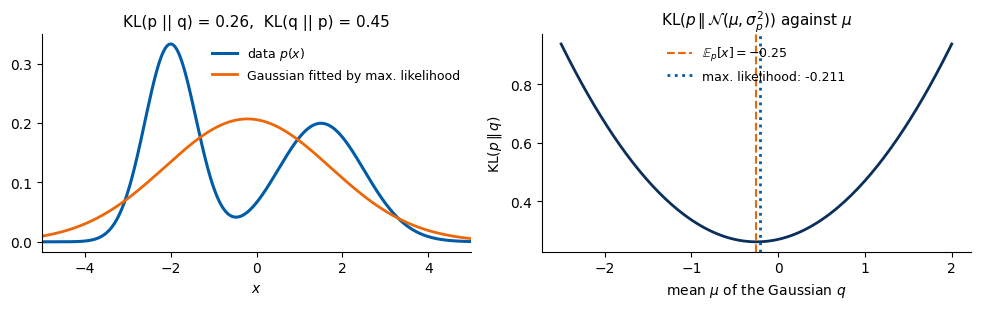

KL minimum at mu = -0.250; max-likelihood mean -0.211, std 1.929 (exact 1.935)
KL(p || q*) = 0.262, KL(q* || p) = 0.454: not symmetric


In [6]:
xk = np.linspace(-8, 8, 4001); dxk = xk[1] - xk[0]; pk = p_mix(xk)
var_p = float(((xk + 0.25) ** 2 * pk).sum() * dxk)
def kl(p, q): return float((p * (np.log(p + 1e-300) - np.log(q + 1e-300))).sum() * dxk)
mus = np.linspace(-2.5, 2.0, 181)
kls = [kl(pk, norm.pdf(xk, m_, np.sqrt(var_p))) for m_ in mus]
rng = seed(22); smp = sample_mix(10000, rng)
q_star = norm.pdf(xk, smp.mean(), smp.std())
nums["kl_mu_min"] = float(mus[np.argmin(kls)]); nums["kl_ml_mean"] = float(smp.mean()); nums["kl_ml_std"] = float(smp.std())
nums["kl_p_qstar"] = kl(pk, q_star); nums["kl_qstar_p"] = kl(q_star, pk)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].plot(xk, pk, color=blue, lw=2.2, label="data $p(x)$")
axs[0].plot(xk, q_star, color=orange, lw=2, label="Gaussian fitted by max. likelihood")
axs[0].set_xlim(-5, 5); axs[0].set_xlabel("$x$"); axs[0].legend(frameon=False, fontsize=9)
axs[0].set_title(f"KL(p || q) = {nums['kl_p_qstar']:.2f},  KL(q || p) = {nums['kl_qstar_p']:.2f}", fontsize=11)
axs[1].plot(mus, kls, color=navy, lw=2); axs[1].axvline(-0.25, color=orange, ls="--", lw=1.5, label=r"$\mathbb{E}_p[x] = -0.25$")
axs[1].axvline(smp.mean(), color=blue, ls=":", lw=2, label=f"max. likelihood: {smp.mean():.3f}")
axs[1].set_xlabel(r"mean $\mu$ of the Gaussian $q$"); axs[1].set_ylabel(r"KL$(p \,\|\, q)$"); axs[1].legend(frameon=False, fontsize=9)
axs[1].set_title(r"KL$(p \,\|\, \mathcal{N}(\mu, \sigma_p^2))$ against $\mu$", fontsize=11)
for a in axs: clean(a)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_kl_ml.png", dpi=170, bbox_inches="tight"); plt.show()
print(f"KL minimum at mu = {nums['kl_mu_min']:.3f}; max-likelihood mean {smp.mean():.3f}, std {smp.std():.3f} (exact {np.sqrt(var_p):.3f})")
print(f"KL(p || q*) = {nums['kl_p_qstar']:.3f}, KL(q* || p) = {nums['kl_qstar_p']:.3f}: not symmetric")

The KL divergence is smallest for a mean of $-0.250$, and maximum likelihood on the samples gives mean $-0.211$ and standard deviation 1.929 (exact value 1.935). The best single Gaussian sits between the two peaks and covers both: it cannot be close to $p$, and the KL divergence, 0.262, measures how far it remains. In the other direction the divergence is 0.454, which confirms that the KL divergence is not symmetric.

## Probability and likelihood

A model $p(x\,|\,\theta)$ gives the probability of data $x$ when the parameters are $\theta$, and the same formula can be read in two ways. Read as a **probability**, $\theta$ is fixed and $x$ varies: the formula tells us which data to expect, and summed over all outcomes $x$ it gives 1. Read as a **likelihood**, the observed data are fixed and $\theta$ varies,
$$L(\theta)=p(x_{\text{obs}}\,|\,\theta), \tag{19}$$
and the formula tells us which parameters make the observed data most plausible. The likelihood is a function of $\theta$, not a probability distribution over $\theta$.

As an example, take a coin with probability $\theta$ of heads, tossed 10 times. The number of heads $k$ follows
$$p(k\,|\,\theta)=\binom{10}{k}\theta^k(1-\theta)^{10-k}, \tag{20}$$
and we observed seven heads. We evaluate the probability of seven heads for a fair coin, the likelihood of a coin with heads probability 0.7, and the integral of the likelihood over $\theta$. The integral is $1/11$, about 0.0909, not 1, which shows that the likelihood is not a distribution over $\theta$.

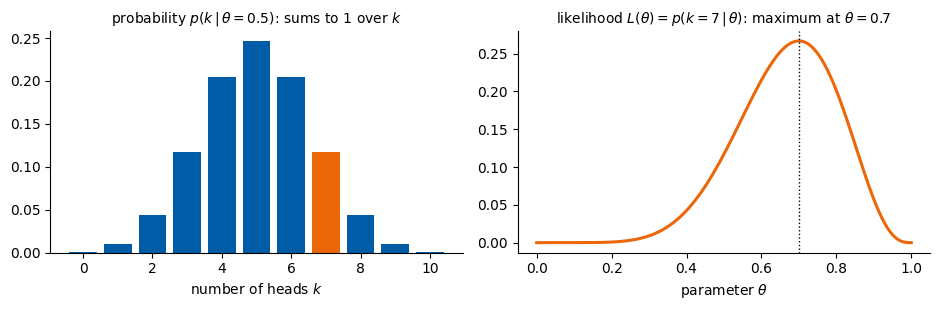

p(7 | 0.5) = 0.117;  L(0.7) = 0.267;  integral of L over theta = 0.0909 (= 1/11, not 1)


In [7]:
from math import comb
ks = np.arange(11); th = np.linspace(0, 1, 401)
p_k = np.array([comb(10, k) * 0.5 ** 10 for k in ks])
L_th = comb(10, 7) * th ** 7 * (1 - th) ** 3
nums["coin_p7_given_half"] = float(p_k[7]); nums["coin_L_at_07"] = float(comb(10, 7) * 0.7 ** 7 * 0.3 ** 3)
nums["coin_L_integral"] = float(np.trapezoid(L_th, th)) if hasattr(np, "trapezoid") else float(np.trapz(L_th, th))
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.2))
axs[0].bar(ks, p_k, color=blue); axs[0].bar([7], [p_k[7]], color=orange)
axs[0].set_xlabel("number of heads $k$"); axs[0].set_title(r"probability $p(k\,|\,\theta = 0.5)$: sums to 1 over $k$", fontsize=10)
axs[1].plot(th, L_th, color=orange, lw=2.2); axs[1].axvline(0.7, color="k", ls=":", lw=1)
axs[1].set_xlabel(r"parameter $\theta$"); axs[1].set_title(r"likelihood $L(\theta) = p(k = 7\,|\,\theta)$: maximum at $\theta = 0.7$", fontsize=10)
for a in axs: clean(a)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_prob_vs_likelihood.png", dpi=170, bbox_inches="tight"); plt.show()
print(f"p(7 | 0.5) = {nums['coin_p7_given_half']:.3f};  L(0.7) = {nums['coin_L_at_07']:.3f};  integral of L over theta = {nums['coin_L_integral']:.4f} (= 1/11, not 1)")

## Maximum likelihood

Suppose the data $\mathbf x_1,\dots,\mathbf x_n$ are independent samples of an unknown $p(\mathbf x)$, and $p_\theta(\mathbf x)$ is a model with parameters $\theta$. The **likelihood** of the data is the probability (density) the model assigns to all of them,
$$L(\theta)=\prod_{i=1}^n p_\theta(\mathbf x_i). \tag{21}$$
Maximum likelihood picks the $\theta$ that makes the observed data most probable; in practice we maximise the log-likelihood
$$\ell(\theta)=\sum_{i=1}^n \log p_\theta(\mathbf x_i). \tag{22}$$
By equation (18), maximising $\ell$ is the same as minimising the KL divergence between the distribution of the data and the model; the cross-entropy loss of classification rests on the same idea.

Our example consists of 1500 points in two dimensions drawn from three groups. We fit two models by maximum likelihood with scikit-learn, a single Gaussian and a mixture of three Gaussians,
$$p_\theta(\mathbf x)=\sum_{k=1}^{3}\pi_k\,\mathcal N(\mathbf x;\boldsymbol\mu_k,\Sigma_k), \tag{23}$$
and then **draw new points** from each fitted model.

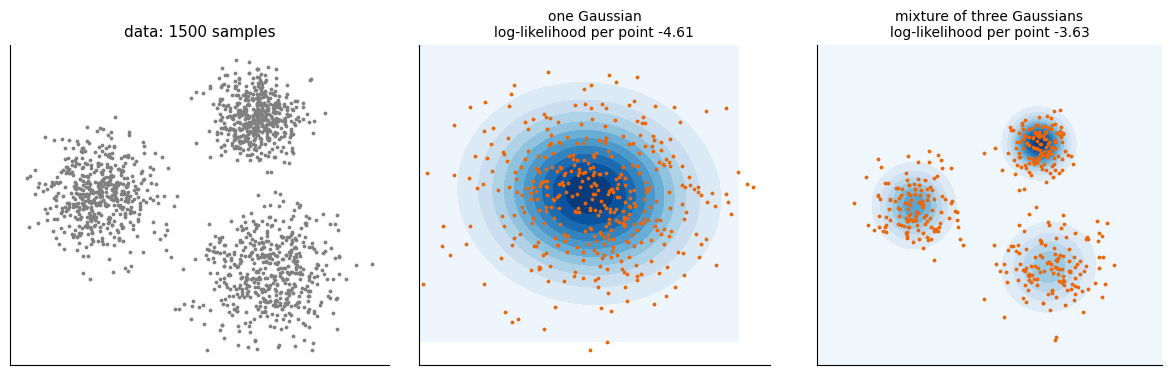

blue: fitted density; orange: 400 new samples drawn from the fitted model


In [8]:
from sklearn.mixture import GaussianMixture
from sklearn.datasets import make_blobs
X2, _ = make_blobs(1500, centers=[[-3, 0], [2, 2.5], [2.5, -2.5]], cluster_std=[0.9, 0.7, 1.1], random_state=0)
models = {"one Gaussian": GaussianMixture(1, random_state=0).fit(X2),
          "mixture of three Gaussians": GaussianMixture(3, random_state=0).fit(X2)}
xx, yy = np.meshgrid(np.linspace(-7, 7, 200), np.linspace(-6.5, 6.5, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
fig, axs = plt.subplots(1, 3, figsize=(12, 3.7))
axs[0].scatter(X2[:, 0], X2[:, 1], s=3, color="grey"); axs[0].set_title("data: 1500 samples", fontsize=11)
for a, (name, m) in zip(axs[1:], models.items()):
    dens = np.exp(m.score_samples(grid)).reshape(xx.shape)
    a.contourf(xx, yy, dens, levels=12, cmap="Blues")
    new, _ = m.sample(400)
    a.scatter(new[:, 0], new[:, 1], s=3, color=orange)
    nums[f"mle_loglik_{len(m.weights_)}"] = float(m.score(X2))       # mean log-likelihood per point
    a.set_title(f"{name}\nlog-likelihood per point {m.score(X2):.2f}", fontsize=10)
for a in axs: a.set_xticks([]); a.set_yticks([]); a.set_aspect("equal"); clean(a)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_mle_gmm.png", dpi=170, bbox_inches="tight"); plt.show()
print("blue: fitted density; orange: 400 new samples drawn from the fitted model")

The mixture assigns the data a higher mean log-likelihood than the single Gaussian ($-3.63$ against $-4.61$ per point, stored in `results/numbers_l6.json`), and its samples look like the data, whereas a single Gaussian puts probability where there are no data. For images we cannot write down such a formula ourselves, and the following sections let neural networks learn it.

As an exercise, fit mixtures with 2, 3, 6 and 12 components and plot the log-likelihood on the data and on a fresh set of samples from `make_blobs` (with another `random_state`). When does a larger model stop helping?

## Autoencoder

### MNIST data

The MNIST (Modified National Institute of Standards and Technology) data set ([LeCun et al. 1998](https://doi.org/10.1109/5.726791)) contains 70 000 greyscale images of handwritten digits, 60 000 for training and 10 000 for testing; the training and test digits were written by different people. One sample is a $28\times28$ image whose pixel values, from 0 (background) to 255 (full ink), are divided by 255, so that each image is a vector of 784 numbers between 0 and 1. Its label is the digit, from 0 to 9, with between 5421 and 6742 training images per class. The files are read from `data/MNIST_raw` and downloaded once if missing.

### Decoded latent grid

An autoencoder (Lecture 5) compresses an image $\mathbf x$ into a latent vector of far fewer numbers and rebuilds it,
$$\mathbf z=E(\mathbf x),\qquad\hat{\mathbf x}=G(\mathbf z); \tag{24}$$
it is trained only to make $\hat{\mathbf x}$ close to $\mathbf x$. Whether its decoder $G$ can also produce *new* digits is tested by training one with a two-dimensional latent space and decoding a regular $12\times12$ grid of latent points that spans the codes of the test digits, from the 1st to the 99th percentile in each coordinate.

Each small image of such a grid is the decoder output $G(z_1,z_2)$ at one point of a regular grid in the two-dimensional latent plane. The column gives the value of $z_1$, increasing from left to right; the row gives the value of $z_2$, increasing from bottom to top. Neighbouring images therefore come from neighbouring latent points, and the grid as a whole is a map of what the decoder produces over the latent plane.

Three training images of every digit illustrate the data.

training images: (60000, 784)  test images: (10000, 784)


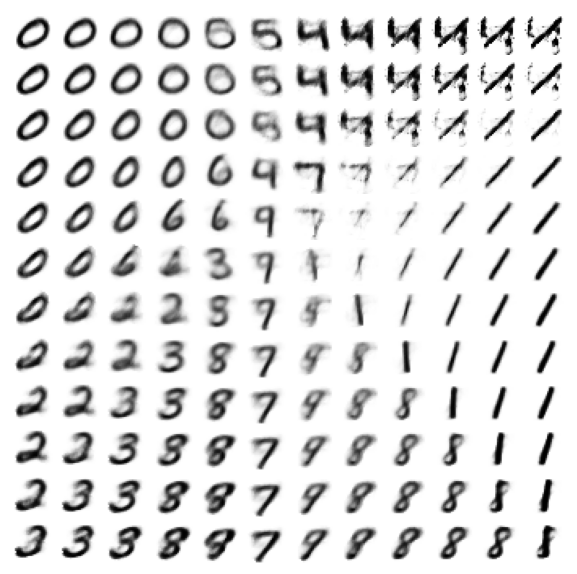

In [9]:
import gzip, urllib.request
RAW = "data/MNIST_raw"; os.makedirs(RAW, exist_ok=True)
LOCAL = os.path.expanduser("~/.pytorch/MNIST_data/MNIST/raw")
MIRRORS = ["https://ossci-datasets.s3.amazonaws.com/mnist/", "https://storage.googleapis.com/cvdf-datasets/mnist/"]
def mnist_file(name):
    for d in (RAW, LOCAL):
        p = os.path.join(d, name)
        if os.path.exists(p): return open(p, "rb").read()
        if os.path.exists(p + ".gz"): return gzip.open(p + ".gz").read()
    for m in MIRRORS:
        try:
            urllib.request.urlretrieve(m + name + ".gz", os.path.join(RAW, name + ".gz"))
            return gzip.open(os.path.join(RAW, name + ".gz")).read()
        except Exception: pass
    raise RuntimeError("MNIST could not be found or downloaded")
def idx(name):
    d = mnist_file(name)
    if d[3] == 3:
        n, r, c = np.frombuffer(d[4:16], ">i4"); return np.frombuffer(d[16:], np.uint8).reshape(n, r * c)
    return np.frombuffer(d[8:], np.uint8)
Xtr = idx("train-images-idx3-ubyte").astype(np.float32) / 255; ytr = idx("train-labels-idx1-ubyte")
Xte = idx("t10k-images-idx3-ubyte").astype(np.float32) / 255; yte = idx("t10k-labels-idx1-ubyte")
Xtr_t, Xte_t = torch.tensor(Xtr), torch.tensor(Xte)
print("training images:", Xtr.shape, " test images:", Xte.shape)

def mlp(sizes, last=None):
    layers = []
    for a, b in zip(sizes[:-1], sizes[1:]):
        layers += [nn.Linear(a, b), nn.ReLU()]
    layers = layers[:-1]
    if last is not None: layers.append(last)
    return nn.Sequential(*layers)

def show_grid(imgs, nrow, ncol, path, title=None, size=1.0):
    fig, axs = plt.subplots(nrow, ncol, figsize=(ncol * size, nrow * size))
    for a, im in zip(axs.ravel(), imgs):
        a.imshow(im.reshape(28, 28), cmap="gray_r", vmin=0, vmax=1); a.axis("off")
    plt.subplots_adjust(wspace=0.03, hspace=0.03)
    if title: fig.suptitle(title, fontsize=10)
    plt.savefig(path, dpi=170, bbox_inches="tight"); plt.show()

rng = seed(0)
enc_ae, dec_ae = mlp([784, 256, 64, 2]), mlp([2, 64, 256, 784], nn.Sigmoid())
opt = torch.optim.Adam(list(enc_ae.parameters()) + list(dec_ae.parameters()), 1e-3)
for ep in range(15):
    perm = torch.randperm(len(Xtr_t))
    for i in range(0, len(perm), 256):
        b = Xtr_t[perm[i:i + 256]]
        loss = ((dec_ae(enc_ae(b)) - b) ** 2).mean(); opt.zero_grad(); loss.backward(); opt.step()
with torch.no_grad():
    Z = enc_ae(Xte_t).numpy()
lo, hi = np.percentile(Z, 1, 0), np.percentile(Z, 99, 0)
g1, g2 = np.linspace(lo[0], hi[0], 12), np.linspace(hi[1], lo[1], 12)
zg = torch.tensor([[a, b] for b in g2 for a in g1], dtype=torch.float32)
with torch.no_grad(): imgs = dec_ae(zg).numpy()
show_grid(imgs, 12, 12, f"{OUT}/gen_ae_grid.png", size=0.6)

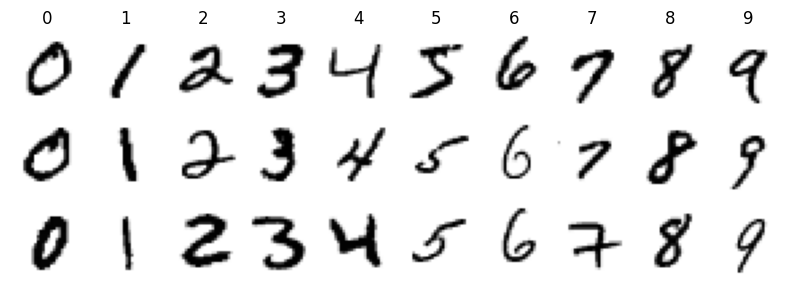

training images per digit: [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]


In [10]:
# three training images of every digit
fig, axs = plt.subplots(3, 10, figsize=(10, 3.3))
for k in range(10):
    for r, i in enumerate(np.flatnonzero(np.asarray(ytr) == k)[:3]):
        axs[r, k].imshow(np.asarray(Xtr[i]).reshape(28, 28), cmap="gray_r", vmin=0, vmax=1); axs[r, k].axis("off")
    axs[0, k].set_title(str(k))
plt.subplots_adjust(wspace=0.05, hspace=0.05); plt.show()
print("training images per digit:", np.bincount(np.asarray(ytr)).tolist())

The left panel of the next figure shows the codes of the 10 000 test digits in the latent plane, coloured by digit, with the grid points as grey dots; the right panel shows the decoded image at every grid point. Three grid points are marked. A and C are the interior grid points with the most test codes within 0.6 grid spacings, chosen among two different digits; B is the interior grid point between them with the fewest codes nearby. For each the computation prints its coordinates, the number of test codes within that distance and the most frequent digit among them.

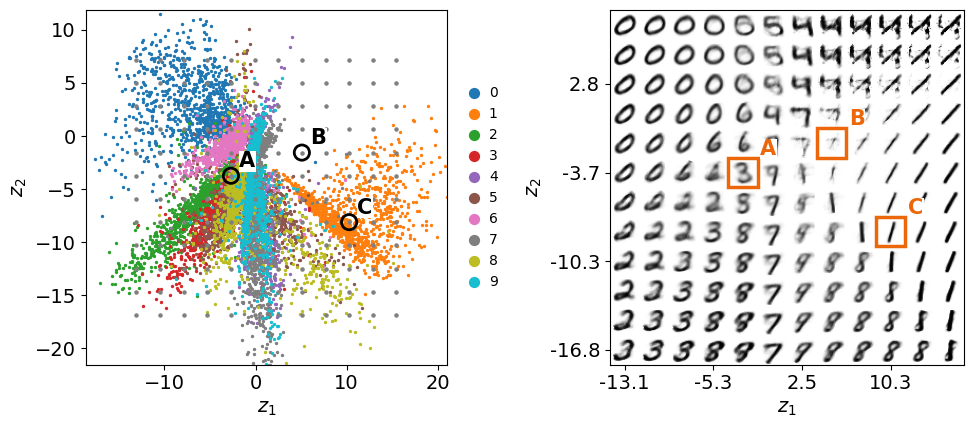

A: z = (-2.70, -3.74), test codes within reach: 988, most frequent digit there: 3
B: z = (5.09, -1.56), test codes within reach: 0, most frequent digit there: -1
C: z = (10.27, -8.11), test codes within reach: 164, most frequent digit there: 1


In [11]:
# the decoded latent grid next to the latent codes of the test digits, with three grid points marked A, B, C
from matplotlib.patches import Rectangle

def grid_explained(codes, labels, zx, zy, decode, path=None):
    """codes: (n, 2) latent codes of test digits, labels: their digits (n,),
    zx: grid values of z1 (left to right), zy: grid values of z2 (bottom to top),
    decode: function from an (m, 2) array of latent points to (m, 784) pixel values in [0, 1]."""
    nx, ny = len(zx), len(zy)
    dx, dy = zx[1] - zx[0], zy[1] - zy[0]
    Zx, Zy = np.meshgrid(zx, zy)                                  # point p = j * nx + i has z = (zx[i], zy[j])
    P = np.stack([Zx.ravel(), Zy.ravel()], 1)
    imgs = decode(P).reshape(ny, nx, 28, 28)
    big = imgs[::-1].transpose(0, 2, 1, 3).reshape(ny * 28, nx * 28)   # top row of tiles: largest z2

    # A and C: interior grid points with many codes nearby, of two different digits; B: the emptiest interior point
    D = np.linalg.norm(P[:, None, :] - codes[None, :, :], axis=2)
    near = D < 0.6 * max(abs(dx), abs(dy))
    cnt = near.sum(1)
    dom = np.array([np.bincount(labels[near[p]], minlength=10).argmax() if cnt[p] else -1 for p in range(len(P))])
    ii, jj = np.meshgrid(np.arange(nx), np.arange(ny)); inner = ((ii > 0) & (ii < nx - 1) & (jj > 0) & (jj < ny - 1)).ravel()
    a = int(np.argmax(np.where(inner, cnt, -1)))
    c = int(np.argmax(np.where(inner & (dom != dom[a]) & (np.linalg.norm(P - P[a], axis=1) > 0.4 * np.ptp(zx)), cnt, -1)))
    mid = (P[a] + P[c]) / 2
    b = int(np.argmin(np.where(inner, cnt + 1e-3 * np.linalg.norm(P - mid, axis=1), np.inf)))
    marks = {"A": a, "B": b, "C": c}

    with plt.rc_context({"font.size": 14}):
        fig, (a0, a1) = plt.subplots(1, 2, figsize=(10, 4.5))
        cm = plt.get_cmap("tab10")
        for k in range(10):
            a0.scatter(*codes[labels == k].T, s=2, color=cm(k), label=str(k), rasterized=True)
        a0.scatter(P[:, 0], P[:, 1], s=5, color="grey", zorder=3)
        ext = (zx[0] - dx / 2, zx[-1] + dx / 2, zy[0] - dy / 2, zy[-1] + dy / 2)
        a0.set_xlim(ext[0] - 0.15 * np.ptp(zx), ext[1] + 0.15 * np.ptp(zx)); a0.set_ylim(ext[2] - 0.15 * np.ptp(zy), ext[3] + 0.15 * np.ptp(zy))
        a0.set_xlabel("$z_1$"); a0.set_ylabel("$z_2$")
        a0.legend(markerscale=5, frameon=False, fontsize=10, ncol=1, loc="center left", bbox_to_anchor=(1.0, 0.5), handletextpad=0.1)
        a1.imshow(big, cmap="gray_r", vmin=0, vmax=1, extent=ext, aspect=dx / dy)
        a1.set_xlabel("$z_1$"); a1.set_ylabel("$z_2$")
        a1.set_xticks(zx[::3]); a1.set_xticklabels([f"{v:.1f}" for v in zx[::3]])
        a1.set_yticks(zy[::3]); a1.set_yticklabels([f"{v:.1f}" for v in zy[::3]])
        for name, p in marks.items():
            x, y = P[p]
            a0.scatter([x], [y], s=120, facecolor="none", edgecolor="k", lw=2, zorder=4)
            a0.annotate(name, (x, y), xytext=(6, 6), textcoords="offset points", fontsize=15, weight="bold",
                        bbox=dict(facecolor="white", edgecolor="none", pad=0.5), zorder=5)
            a1.add_patch(Rectangle((x - dx / 2, y - dy / 2), dx, dy, fill=False, edgecolor=orange, lw=2.5))
            a1.annotate(name, (x + dx / 2, y + dy / 2), xytext=(2, 2), textcoords="offset points", fontsize=15, weight="bold",
                        color=orange, bbox=dict(facecolor="white", edgecolor="none", pad=0.3))
        plt.tight_layout()
        if path: fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
        plt.show()
    for name, p in marks.items():
        print(f"{name}: z = ({P[p, 0]:.2f}, {P[p, 1]:.2f}), test codes within reach: {cnt[p]}, most frequent digit there: {dom[p]}")

with torch.no_grad(): Z_te = enc_ae(Xte_t).numpy()
grid_explained(Z_te, yte, g1, g2[::-1], lambda z: dec_ae(torch.tensor(z, dtype=torch.float32)).detach().numpy(),
               f"{OUT}/gen_ae_grid_explained.png")

Point A, at (−2.70, −3.74), has 988 test codes within reach, mostly of the digit 3, and decodes to a clear 3; point C, at (10.27, −8.11), has 164 codes, mostly 1, and decodes to a 1. Point B, at (5.09, −1.56), lies between the classes with no test code within reach, and its decoded image is a faint stroke that is not a clear digit. The codes of the autoencoder spread over a region some 30 units wide, with dense arms for some digits and empty wedges between them: nothing in the training fixes where the codes go or which latent points decode to digits.

### Discrete codes and a continuous latent density

The latent space of the two-dimensional autoencoder is the plane $\mathbb R^2$, a continuum in which every point $\mathbf z$ is a valid input of the decoder. Training fills it only at the codes of the training images, one point per image,
$$\mathbf z_i=E(\mathbf x_i),\qquad i=1,\dots,N, \tag{25}$$
with $N$ the 60 000 training digits, and the decoder is trained only at these points. The distribution of latent vectors that the autoencoder defines is therefore the empirical distribution
$$q(\mathbf z)=\frac1N\sum_{i=1}^N\delta(\mathbf z-\mathbf z_i), \tag{26}$$
a sum of spikes. Sampling it returns training codes and nothing else, which decode to reconstructions of training images. A point between the spikes is a valid input, but the decoder was never asked to produce anything there, and the codes form a cloud of irregular shape and scale, with gaps between the classes.

Generation needs a continuous density $p(\mathbf z)$ that covers a region of the plane, and a decoder trained on the whole region, such that
$$p_\theta(\mathbf x)=\int p_\theta(\mathbf x|\mathbf z)\,p(\mathbf z)\,d\mathbf z\approx p_{\text{data}}(\mathbf x). \tag{27}$$
A new $\mathbf z$ drawn from $p(\mathbf z)$ then decodes to a new sample of the data distribution. The VAE replaces each point $\mathbf z_i$ by a Gaussian cloud and pulls all clouds towards $\mathcal N(0,I)$, so that together they fill a continuous region; the subsection on latent densities compares the two planes.

## Variational autoencoder

The variational autoencoder (VAE) is a latent-variable model: a latent vector $\mathbf z$ is drawn from a simple prior,
$$p(\mathbf z)=\mathcal N(0,I), \tag{28}$$
and the decoder turns it into an image, $p_\theta(\mathbf x|\mathbf z)$. The distribution of the data is then
$$p_\theta(\mathbf x)=\int p_\theta(\mathbf x|\mathbf z)\,p(\mathbf z)\,d\mathbf z . \tag{29}$$

The encoder no longer maps an input $\mathbf x$ to a single point. Instead, it outputs a Gaussian *cloud* in latent space, the encoder distribution $q_\phi(\mathbf z|\mathbf x)$, with a mean $\boldsymbol\mu(\mathbf x)$ and a width $\boldsymbol\sigma(\mathbf x)$ for each of the $d$ latent coordinates; in practice it outputs $\log\boldsymbol\sigma^2$, which can be any real number. A latent vector is drawn from the cloud by the shift-and-stretch of equation (9), with $\boldsymbol\varepsilon$ drawn from $\mathcal N(0,I)$ independently of the network. This is the reparametrisation trick: the randomness sits in $\boldsymbol\varepsilon$, so $\mathbf z$ is an ordinary differentiable function of $\boldsymbol\mu$ and $\boldsymbol\sigma$, and backpropagation works through it.

The loss has two terms per image,
$$\mathcal L(\mathbf x)=\underbrace{\mathrm{BCE}\big(\mathbf x,G(\mathbf z)\big)}_{\text{rebuild the input}}+\underbrace{\tfrac12\sum_{k=1}^{d}\big(\mu_k^2+\sigma_k^2-\ln\sigma_k^2-1\big)}_{\mathrm{KL}(\mathcal N(\boldsymbol\mu,\boldsymbol\sigma^2)\,\|\,\mathcal N(0,I))}. \tag{30}$$
The binary cross-entropy (BCE), summed over the 784 pixels, suits pixels in $[0,1]$. The KL term pulls every cloud towards $\mathcal N(0,I)$, so that the clouds of all images fill one standard Gaussian without gaps. The sum of the two terms is minus a lower bound on $\log p_\theta(\mathbf x)$, the *evidence lower bound* (ELBO), so training the VAE is approximate maximum likelihood. Encoder $q_\phi(\mathbf z|\mathbf x)$ and decoder $p_\theta(\mathbf x|\mathbf z)$ are trained jointly, by minimising the loss summed over the training images with respect to both $\phi$ and $\theta$. The two terms complement each other: the KL term keeps the codes of all images inside the prior $p(\mathbf z)$, and the reconstruction term makes the decoder turn every code in that region into a plausible image. Together they give what the autoencoder lacked, a latent space in which a $\mathbf z$ drawn from $p(\mathbf z)$ decodes to a digit.

The class `VAE` implements this model; its argument `cond` adds the optional condition used by the conditional VAE.

In [12]:
class VAE(nn.Module):
    def __init__(self, D=784, d=2, cond=0, hidden=(512, 256)):
        super().__init__()
        self.d, self.cond = d, cond
        self.enc = mlp([D + cond, *hidden]); self.enc.append(nn.ReLU())
        self.mu, self.logvar = nn.Linear(hidden[-1], d), nn.Linear(hidden[-1], d)
        self.dec = mlp([d + cond, *hidden[::-1], D])                  # outputs logits; sigmoid gives pixels
    def encode(self, x, c=None):
        h = self.enc(x if c is None else torch.cat([x, c], 1))
        return self.mu(h), self.logvar(h)
    def decode(self, z, c=None):
        return self.dec(z if c is None else torch.cat([z, c], 1))
    def forward(self, x, c=None):
        mu, logvar = self.encode(x, c)
        eps = torch.randn_like(mu)                                  # the randomness, outside the network
        z = mu + torch.exp(0.5 * logvar) * eps                      # reparametrisation trick
        return self.decode(z, c), mu, logvar

def vae_loss(logits, x, mu, logvar):
    rec = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / len(x)
    kl = 0.5 * (mu ** 2 + logvar.exp() - logvar - 1).sum() / len(x)
    return rec + kl, rec, kl

def train_vae(model, X, C=None, epochs=20, lr=1e-3, bs=128):
    opt = torch.optim.Adam(model.parameters(), lr)
    hist = []
    for ep in range(epochs):
        perm = torch.randperm(len(X)); tot = np.zeros(3)
        for i in range(0, len(perm), bs):
            j = perm[i:i + bs]; x = X[j]; c = None if C is None else C[j]
            logits, mu, logvar = model(x, c)
            loss, rec, kl = vae_loss(logits, x, mu, logvar)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += np.array([loss.item(), rec.item(), kl.item()]) * len(j)
        hist.append(tot / len(X))
    return np.array(hist)

### Network drawings

The networks of this lecture are easier to follow as pictures. The function `draw_network` below draws a fully connected network the way it is usually sketched: every layer is a column of circles, one circle per neuron, and thin grey lines join every neuron of one layer with every neuron of the next, because a dense layer `nn.Linear` connects all of them. Real layers are far too wide to draw neuron by neuron, so a layer with more than `max_nodes` neurons is shown by a few neurons at each end and a vertical ellipsis in between, and its true size is written under the column. The height of a column grows with the logarithm of the layer size, so a network that narrows to a bottleneck and widens again, like the encoder and decoder of a VAE, is visibly narrow in the middle. The colours follow one convention: grey for the data (input and output), blue for hidden layers, orange for the latent layer and green for a condition.

A column may also hold several blocks stacked on top of each other, given as a list of sizes. This is how we draw the two outputs $\boldsymbol\mu$ and $\log\boldsymbol\sigma^2$ of the encoder, or an image together with its one-hot label. The argument `groups` puts a labelled bracket above a range of columns, such as "encoder", and `no_input` marks a block that receives no edges from the previous column, for example a label that enters the decoder from outside. The comments in the code explain each part: how the node positions are computed, how large layers are truncated, how the edges are drawn, and where the labels go.

To draw a network of your own, pass the widths of its dense layers from the input to the output, for example `draw_network([784, 128, 10], labels=["image", None, "classes"])`, or better read them from the model, as the function `linear_sizes` defined with the VAE drawing does from the `nn.Linear` layers. The function returns the matplotlib axes, so the figure can be saved with `ax.figure.savefig(...)`. The drawing shows only the connectivity and the widths, not the activation functions; those we read from the code, or from the layer table of `torchinfo`.

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# Colours used for the network drawings: grey for the data (input and output),
# blue for hidden layers, orange for the latent (bottleneck) layer and green
# for an extra conditioning input such as a one-hot class label.
GREY, BLUE, ORANGE, GREEN = "#8C8C8C", "#005CA7", "#EB6709", "#2E8B57"


def draw_network(layer_sizes, labels=None, colors=None, max_nodes=10,
                 groups=None, no_input=None, ax=None, node_radius=0.11,
                 x_gap=1.6, min_height=1.0, height_scale=1.1, fontsize=13):
    """Draw a fully connected network as columns of circles joined by edges.

    Parameters
    ----------
    layer_sizes : list
        One entry per column, from the input to the output. An entry is
        either an int (the number of neurons of one layer) or a list of ints
        (several blocks stacked in the same column, e.g. [16, 16] for the mean
        and the log-variance of a variational autoencoder, or [784, 10] for an
        image together with a one-hot condition).
    labels : list, optional
        Names shown under each column next to the true layer size. An entry
        may be None (size only), a string, or, for a stacked column, a list
        with one string per block.
    colors : list, optional
        Fill colour of the nodes of each column (or a list with one colour per
        block). By default the first and the last column are grey and all
        others blue.
    max_nodes : int
        Largest number of circles drawn for one block. A larger block is shown
        by its first and last few nodes with a vertical ellipsis in between;
        the true size is always shown in the label.
    groups : list of (text, first_column, last_column), optional
        Brackets drawn above a range of columns, e.g. ("encoder", 0, 2).
    no_input : list of (column, block), optional
        Blocks that receive no edges from the previous column, e.g. a condition
        c that enters the decoder from outside.
    ax : matplotlib Axes, optional
        Axes to draw into; a new figure is created when None.
    node_radius, x_gap : float
        Radius of a circle and horizontal distance between columns.
    min_height, height_scale : float
        The height of a block of size s is min_height + height_scale*log10(s),
        so that a narrow layer is visibly shorter than a wide one.
    fontsize : int
        Font size of all labels.

    Returns
    -------
    ax : the matplotlib Axes with the drawing.
    """
    n = len(layer_sizes)
    # Turn every entry into a list of blocks, so that a plain layer is a
    # column with a single block.
    blocks = [s if isinstance(s, (list, tuple)) else [s] for s in layer_sizes]
    if labels is None:
        labels = [None] * n
    if colors is None:
        colors = [GREY] + [BLUE] * (n - 2) + [GREY]
    no_input = set(no_input or [])

    def per_block(value, k):
        # Repeat a single value for all k blocks of a column, or keep a list.
        return list(value) if isinstance(value, (list, tuple)) else [value] * k

    if ax is None:
        _, ax = plt.subplots(figsize=(1.9 * n + 1, 5.5))

    # ---- Node positions ---------------------------------------------------
    # Column i sits at x = i * x_gap. Inside a column the blocks are stacked
    # from top to bottom with a small gap, and the whole column is centred
    # on y = 0. Each block gets a height that grows with log10 of its size
    # (but is never too small for its circles to fit without overlapping);
    # the drawn nodes are spread evenly over that height.
    nodes = []            # nodes[i][b] = list of (x, y) of block b in column i
    tops, bottoms = [], []
    gap = 0.9             # vertical space between stacked blocks (holds a label)
    for i, blk in enumerate(blocks):
        cols = per_block(colors[i], len(blk))
        labs = per_block(labels[i], len(blk))
        heights = [max(min_height + height_scale * np.log10(s),
                       (min(s, max_nodes) - 1) * 2.3 * node_radius) for s in blk]
        total = sum(heights) + gap * (len(blk) - 1)
        x, y_top = i * x_gap, total / 2
        column = []
        for s, h, c, lab in zip(blk, heights, cols, labs):
            shown = min(s, max_nodes)
            if s <= max_nodes:
                # Small block: draw every neuron.
                ys = np.linspace(y_top, y_top - h, shown) if shown > 1 else np.array([y_top - h / 2])
            else:
                # ---- Truncation of large layers ----------------------------
                # Draw max_nodes circles: half in the upper 38 % of the block,
                # half in the lower 38 %, and a vertical ellipsis in the
                # middle to show that neurons are omitted.
                k = max_nodes // 2
                ys = np.concatenate([np.linspace(y_top, y_top - 0.38 * h, k),
                                     np.linspace(y_top - 0.62 * h, y_top - h, max_nodes - k)])
                ax.text(x, y_top - 0.5 * h, r"$\vdots$", ha="center", va="center",
                        fontsize=fontsize + 6, color=c, zorder=4)
            for y in ys:
                ax.add_patch(Circle((x, y), node_radius, facecolor=c,
                                    edgecolor="black", lw=0.6, zorder=3))
            column.append([(x, y) for y in ys])

            # ---- Labels of stacked blocks ----------------------------------
            # In a column with several blocks each block is labelled just
            # below its last node, in its own colour, on a white box so that
            # the edges behind do not hide the text.
            if len(blk) > 1:
                text = f"{s}" if lab is None else f"{lab} {s}"
                ax.text(x, y_top - h - 0.2, text, ha="center", va="top",
                        fontsize=fontsize - 1, color=c, zorder=5,
                        bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
            y_top -= h + gap

        # ---- Label of a single-block column: name and true size below ----
        if len(blk) == 1:
            lab = labs[0]
            text = f"{blk[0]}" if lab is None else f"{lab}\n{blk[0]}"
            ax.text(x, -total / 2 - 0.3, text, ha="center", va="top", fontsize=fontsize)
        nodes.append(column)
        tops.append(total / 2)
        bottoms.append(-total / 2)

    # ---- Edges ---------------------------------------------------------------
    # A dense layer connects every neuron of one column with every neuron of
    # the next, so we draw a thin grey line for every pair of drawn nodes,
    # skipping the blocks listed in no_input. zorder=1 keeps lines behind
    # the circles.
    for i in range(n - 1):
        sources = [p for block in nodes[i] for p in block]
        for b, block in enumerate(nodes[i + 1]):
            if (i + 1, b) in no_input:
                continue
            for (x0, y0) in sources:
                for (x1, y1) in block:
                    ax.plot([x0, x1], [y0, y1], color="#B0B0B0", lw=0.35, zorder=1)

    # ---- Group brackets ------------------------------------------------------
    # A bracket above columns first..last with its text, e.g. "encoder".
    y_br = max(tops) + 0.45
    for text, i0, i1 in (groups or []):
        x0, x1 = i0 * x_gap - 0.3, i1 * x_gap + 0.3
        ax.plot([x0, x0, x1, x1], [y_br - 0.12, y_br, y_br, y_br - 0.12],
                color="black", lw=1.2)
        ax.text((x0 + x1) / 2, y_br + 0.1, text, ha="center", va="bottom",
                fontsize=fontsize)

    # ---- Axes limits ----------------------------------------------------------
    # Leave room for the brackets above and the labels below.
    ax.set_xlim(-0.8, (n - 1) * x_gap + 0.8)
    ax.set_ylim(min(bottoms) - 1.3, y_br + (0.7 if groups else 0.2))
    ax.set_aspect("equal")
    ax.axis("off")
    return ax


### VAE architecture

We draw the VAE with 16 latent dimensions trained in this section. The encoder takes the 784 pixels through layers of 512 and 256 units to two parallel outputs of 16 numbers each, $\boldsymbol\mu$ and $\log\boldsymbol\sigma^2$. The latent vector $\mathbf z$ is not the output of a dense layer: the edges into it stand for the sampling of equation (9), in which $z_k$ depends only on $\mu_k$ and $\sigma_k$. The decoder mirrors the encoder, $16\to256\to512\to784$. The widths are not typed in: `linear_sizes` reads them from the `nn.Linear` layers of the model and `vae_columns` arranges them into columns, and an `assert` checks that the drawn connections carry exactly as many parameters as `torchinfo` counts, $a\cdot b$ weights and $b$ biases between columns of widths $a$ and $b$, with no parameters in the sampling step. The picture is also saved as `arch_vae.png` for the slides.

Next to our own drawing we use a library that reads the architecture directly from the PyTorch model. `torchinfo.summary(model, input_data=...)` passes an example input through the network and prints a table with one row per layer: its type, the shape of its output and its number of parameters, followed by the totals. It is the quickest way to check that the shapes fit together and to see where the parameters are. The argument `col_names` chooses the columns of the table, and `verbose=0` returns the table instead of printing it twice. Building a fresh model draws random initial weights; `torch.random.fork_rng()` restores the state of the random generator afterwards, so the random numbers drawn later do not change.

`torchview.draw_graph(model, input_data=..., expand_nested=True)` follows one forward pass and draws it as a graph of modules and tensor operations, with the shapes of their inputs and outputs; Graphviz renders it to a PNG file (`results/arch_vae_torchview.png`). For the VAE the graph shows what the table cannot: the encoder output feeding two parallel layers, and the reparametrisation of equation (9), with $\boldsymbol\sigma$ computed as $\exp(\tfrac12\log\boldsymbol\sigma^2)$, as tensor operations between encoder and decoder. The two tools answer different questions. The table is where shapes are checked and parameters counted, and it stays readable for networks of any size; the graph shows how the tensors flow, which matters for networks with branches, skip connections or several inputs, but it becomes unwieldy for deep models.

columns read from the model: [784, 512, 256, [16, 16], 16, 256, 512, 784]


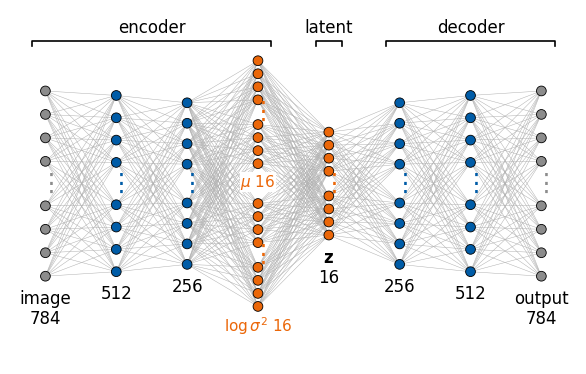

Layer (type:depth-idx)                   Output Shape              Param #
VAE                                      [1, 784]                  --
├─Sequential: 1-1                        [1, 256]                  --
│    └─Linear: 2-1                       [1, 512]                  401,920
│    └─ReLU: 2-2                         [1, 512]                  --
│    └─Linear: 2-3                       [1, 256]                  131,328
│    └─ReLU: 2-4                         [1, 256]                  --
├─Linear: 1-2                            [1, 16]                   4,112
├─Linear: 1-3                            [1, 16]                   4,112
├─Sequential: 1-4                        [1, 784]                  --
│    └─Linear: 2-5                       [1, 256]                  4,352
│    └─ReLU: 2-6                         [1, 256]                  --
│    └─Linear: 2-7                       [1, 512]                  131,584
│    └─ReLU: 2-8                         [1, 512]            

In [14]:
from torchinfo import summary

# helpers that read the architecture from the model instead of typing the sizes
def linear_sizes(net):
    # widths of the dense layers of a network, in order: [inputs of the first nn.Linear, outputs of each nn.Linear]
    lin = [m for m in net.modules() if isinstance(m, nn.Linear)]
    return [lin[0].in_features] + [l.out_features for l in lin]

def vae_columns(m):
    # columns of draw_network for a (conditional) VAE: input, encoder layers, (mu, log sigma^2), z, decoder layers
    enc, dec = linear_sizes(m.enc), linear_sizes(m.dec)
    first = [enc[0] - m.cond, m.cond] if m.cond else enc[0]
    zcol = [dec[0] - m.cond, m.cond] if m.cond else dec[0]
    return [first, *enc[1:], [m.mu.out_features, m.logvar.out_features], zcol, *dec[1:]]

def vae_style(cols):
    # labels, colours and brackets for the columns returned by vae_columns
    n, cond = len(cols), isinstance(cols[0], list)
    k = next(i for i in range(1, n) if isinstance(cols[i], list))          # the (mu, log sigma^2) column
    labels, colors = [None] * n, [BLUE] * n
    labels[0], colors[0] = (["image", r"$\mathbf{c}$"], [GREY, GREEN]) if cond else ("image", GREY)
    labels[k], colors[k] = [r"$\mu$", r"$\log\sigma^2$"], [ORANGE, ORANGE]
    labels[k + 1], colors[k + 1] = ([r"$\mathbf{z}$", r"$\mathbf{c}$"], [ORANGE, GREEN]) if cond else (r"$\mathbf{z}$", ORANGE)
    labels[-1], colors[-1] = "output", GREY
    groups = ([("encoder", 0, k), ("decoder", k + 1, n - 1)] if cond else
              [("encoder", 0, k), ("latent", k + 1, k + 1), ("decoder", k + 2, n - 1)])
    return dict(labels=labels, colors=colors, groups=groups, no_input=[(k + 1, 1)] if cond else None)

def dense_params(cols, sampled=()):
    # parameters of the drawn connections: a*b weights and b biases between consecutive columns,
    # except the edges into a sampled column (z = mu + sigma * eps has no parameters)
    w = lambda c: sum(c) if isinstance(c, list) else c
    return sum(w(a) * w(b) + w(b) for i, (a, b) in enumerate(zip(cols[:-1], cols[1:])) if i + 1 not in sampled)

with torch.random.fork_rng():                                    # building a model draws random weights; later cells keep their random numbers
    vae_d16 = VAE(d=16)
    table = summary(vae_d16, input_data=torch.zeros(1, 784), col_names=("output_size", "num_params"), verbose=0)
cols = vae_columns(vae_d16)
print("columns read from the model:", cols)
assert dense_params(cols, sampled={len(cols) - 4}) == table.total_params   # the drawing carries exactly the parameters of the model

fig, ax = plt.subplots(figsize=(12, 4.6))                      # slide size: labels of 12 pt at full slide width
draw_network(cols, **vae_style(cols), max_nodes=8, fontsize=12, ax=ax)
ax.figure.savefig(f"{OUT}/arch_vae.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print(table)

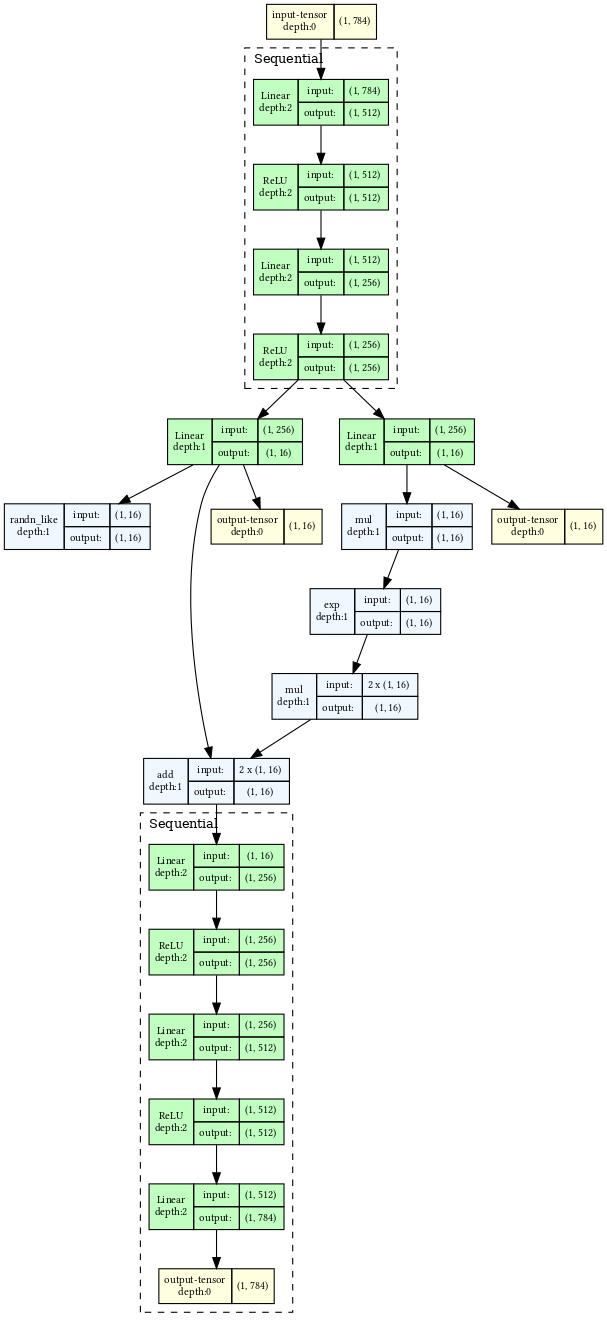

In [15]:
from torchview import draw_graph
from IPython.display import Image, display

with torch.random.fork_rng():
    graph = draw_graph(VAE(d=16), input_data=torch.zeros(1, 784), expand_nested=True, graph_name="VAE")
display(Image(graph.visual_graph.render(filename="arch_vae_torchview", directory=RES, format="png", cleanup=True)))

### Training and sampling

Training adjusts the encoder parameters $\phi$, which produce $\boldsymbol\mu$ and $\log\boldsymbol\sigma^2$, and the decoder parameters $\theta$ together, with the Adam optimiser on mini-batches of 128 images. For each image of a batch the encoder gives its cloud, one noise vector $\boldsymbol\varepsilon$ is drawn from $\mathcal N(0,I)$, the latent vector of equation (9) is decoded, and the loss is averaged over the batch. The sampling thus sits inside the loss, and because it is written as a differentiable function of $\boldsymbol\mu$ and $\boldsymbol\sigma$, one backward pass gives the gradient with respect to both $\phi$ and $\theta$. A single $\boldsymbol\varepsilon$ per image and step is a noisy estimate of the expected reconstruction error over the cloud; averaged over many steps it suffices.

We train two VAEs on the 60 000 training digits, without labels: one with a two-dimensional latent space, which can be drawn, and one with 16 latent dimensions, which rebuilds and generates better.

trained in 1494 s
d = 2: loss per image 138.9 = reconstruction 132.1 + KL 6.8
d = 16: loss per image 99.9 = reconstruction 80.3 + KL 19.6


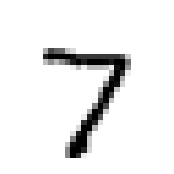

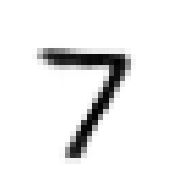

In [16]:
rng = seed(1)
t0 = time.time()
vae2 = VAE(d=2); h2 = train_vae(vae2, Xtr_t, epochs=20)
vae16 = VAE(d=16); h16 = train_vae(vae16, Xtr_t, epochs=20)
print(f"trained in {time.time() - t0:.0f} s")
for name, h in [("d = 2", h2), ("d = 16", h16)]:
    print(f"{name}: loss per image {h[-1, 0]:.1f} = reconstruction {h[-1, 1]:.1f} + KL {h[-1, 2]:.1f}")
nums["vae16_loss"], nums["vae16_rec"], nums["vae16_kl"] = [float(v) for v in h16[-1]]

# one test digit and its VAE reconstruction (used in the diagrams of the slides)
vae16.eval()
with torch.no_grad():
    mu, _ = vae16.encode(Xte_t[:1]); x_rec = torch.sigmoid(vae16.decode(mu))[0].numpy()
for arr, name in [(Xte[0], "gen_vae_in.png"), (x_rec, "gen_vae_out.png")]:
    plt.figure(figsize=(2, 2)); plt.imshow(arr.reshape(28, 28), cmap="gray_r"); plt.axis("off")
    plt.savefig(f"{OUT}/{name}", dpi=170, bbox_inches="tight", pad_inches=0.02); plt.show()

With two latent dimensions the final loss per image is 138.9 (reconstruction 132.1, KL 6.8); with 16 it is 99.9 (reconstruction 80.3, KL 19.6). The larger latent space carries more information about each image, so it rebuilds better and pays a larger KL term for it.

### New digits

After training, the encoder plays no part in generation. A new image is an ancestral sample of the model distribution, the integral of the decoder over the prior: first a latent vector is drawn from the prior, then an image from the decoder,
$$\mathbf z\sim\mathcal N(0,I),\qquad \mathbf x\sim p_\theta(\mathbf x|\mathbf z). \tag{31}$$
The decoder gives, for each pixel $j$, the probability
$$\hat x_j=\operatorname{sigmoid}\big(G(\mathbf z)\big)_j \tag{32}$$
of a Bernoulli distribution, the distribution behind the BCE loss, and the second step of equation (31) would set pixel $j$ to 1 with probability $\hat x_j$. The images shown are the means $\hat{\mathbf x}$, not such draws; the difference is shown at the end of this section.

The left panel shows the decoder of the two-dimensional VAE on a regular $15\times15$ grid of $\mathbf z$ over $[-2.5,2.5]^2$, the region where $\mathcal N(0,I)$ puts its probability. It is read like the grid of the autoencoder: each small image is $G(z_1,z_2)$, with $z_1$ increasing from left to right and $z_2$ from bottom to top. The right panel shows 32 new digits from the VAE with 16 latent dimensions, each decoded from a random $\mathbf z$ drawn from $\mathcal N(0,I)$. To see whether the model only copies its training data, we also measure the distance of each generated digit to the nearest training image and compare it with the same distance for real test digits.

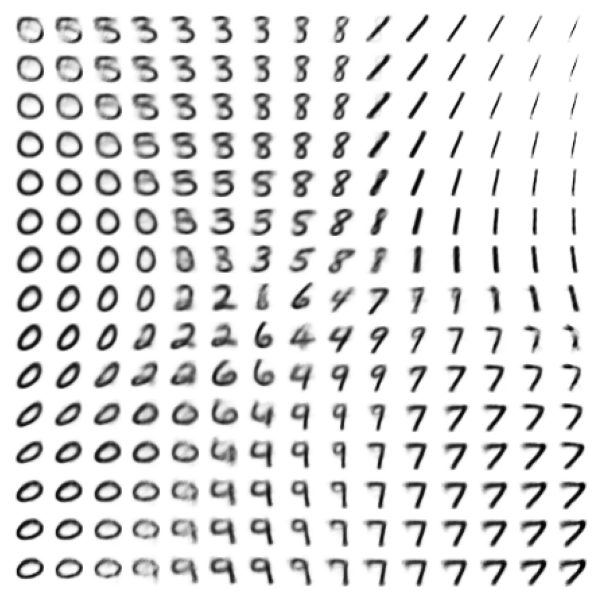

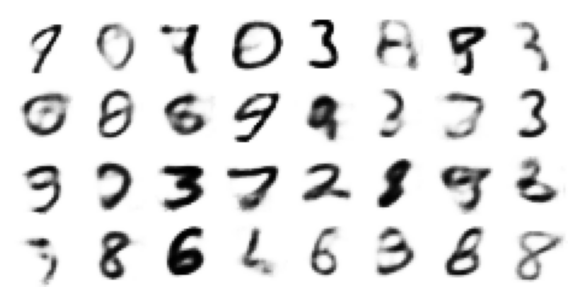

mean distance to the nearest training image: generated 4.73, real test digits 4.03


In [17]:
vae2.eval()
g = np.linspace(-2.5, 2.5, 15)
zg = torch.tensor([[a, b] for b in g[::-1] for a in g], dtype=torch.float32)
with torch.no_grad(): imgs = torch.sigmoid(vae2.decode(zg)).numpy()
show_grid(imgs, 15, 15, f"{OUT}/gen_vae_grid.png", size=0.5)
torch.manual_seed(10)
with torch.no_grad(): new = torch.sigmoid(vae16.decode(torch.randn(32, 16))).numpy()
show_grid(new, 4, 8, f"{OUT}/gen_vae_samples.png", size=0.9)

# are the new digits copies of training images? distance to the nearest training image
d_new = torch.cdist(torch.tensor(new), Xtr_t).min(1).values.numpy()
d_test = torch.cdist(Xte_t[:32], Xtr_t).min(1).values.numpy()
nums["vae_nn_dist_new"], nums["vae_nn_dist_test"] = float(d_new.mean()), float(d_test.mean())
print(f"mean distance to the nearest training image: generated {d_new.mean():.2f}, real test digits {d_test.mean():.2f}")

The same reading is applied to the two-dimensional VAE, with the grid over the square from −2.5 to 2.5 in both coordinates, where the prior puts its probability, and the three points chosen by the same rule.

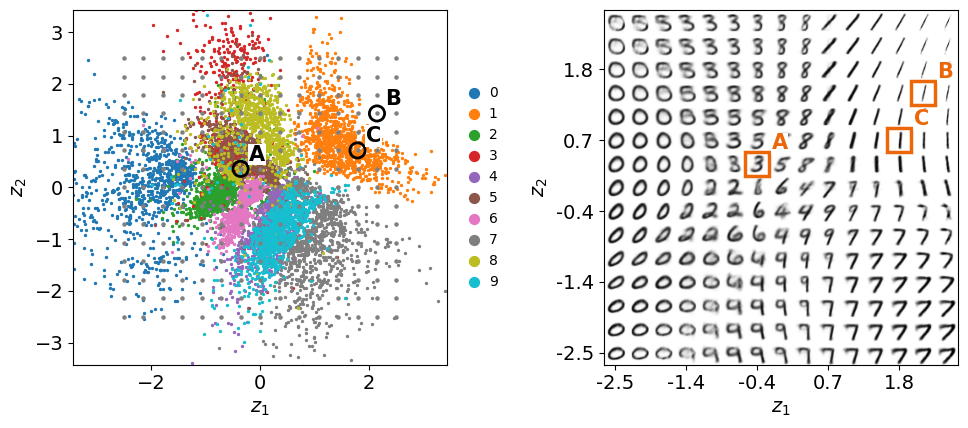

A: z = (-0.36, 0.36), test codes within reach: 422, most frequent digit there: 3
B: z = (2.14, 1.43), test codes within reach: 0, most frequent digit there: -1
C: z = (1.79, 0.71), test codes within reach: 105, most frequent digit there: 1


In [18]:
with torch.no_grad(): Z2_te = vae2.encode(Xte_t)[0].numpy()
grid_explained(Z2_te, yte, g, g, lambda z: torch.sigmoid(vae2.decode(torch.tensor(z, dtype=torch.float32))).detach().numpy(),
               f"{OUT}/gen_vae_grid_explained.png")

Every point of the grid decodes to a digit, and neighbouring points give similar digits. The generated digits are not copies: their mean distance to the nearest training image, 4.73, is comparable to that of real test digits, 4.03, which the network never saw. The samples are somewhat blurry, a known property of VAEs.

As an exercise, train the VAE with 16 latent dimensions without the KL term (set `kl = 0` in `vae_loss`) and generate from $\mathcal N(0,I)$ again. What happens, and why?

### Latent densities of the autoencoder and the VAE

The left panel shows the codes of 2000 test digits in the plane of the two-dimensional autoencoder, four latent points far from every training code, marked by crosses, and the images the decoder produces there. The middle panel shows the aggregate posterior of the two-dimensional VAE,
$$q(\mathbf z)=\frac1N\sum_{i=1}^N\mathcal N\big(\mathbf z;\boldsymbol\mu_i,\operatorname{diag}\boldsymbol\sigma_i^2\big), \tag{33}$$
the continuous counterpart of equation (26), on a logarithmic colour scale, with the circles of radius 1 and 2 of $\mathcal N(0,I)$. The right panel shows 25 images decoded from random $\mathbf z$ drawn from $\mathcal N(0,I)$. Three numbers quantify the difference. The first is the median distance from random latent points to the nearest training code, in units of the median spacing between neighbouring codes, for the autoencoder, with points drawn from a Gaussian fitted to its codes, and for the VAE, with points drawn from $\mathcal N(0,I)$. The second is the median cloud width $\sigma$ of the VAE in the same units. The third is the fraction of draws from $\mathcal N(0,I)$ at which $q(\mathbf z)$ is below a tenth of the prior density.

N = 60000 training codes
median distance to the nearest code / median code spacing: autoencoder 1.6, VAE 1.32
median cloud width sigma of the VAE / median code spacing: 5.6
fraction of N(0, I) draws where q(z) < 0.1 N(z; 0, I): 0.036


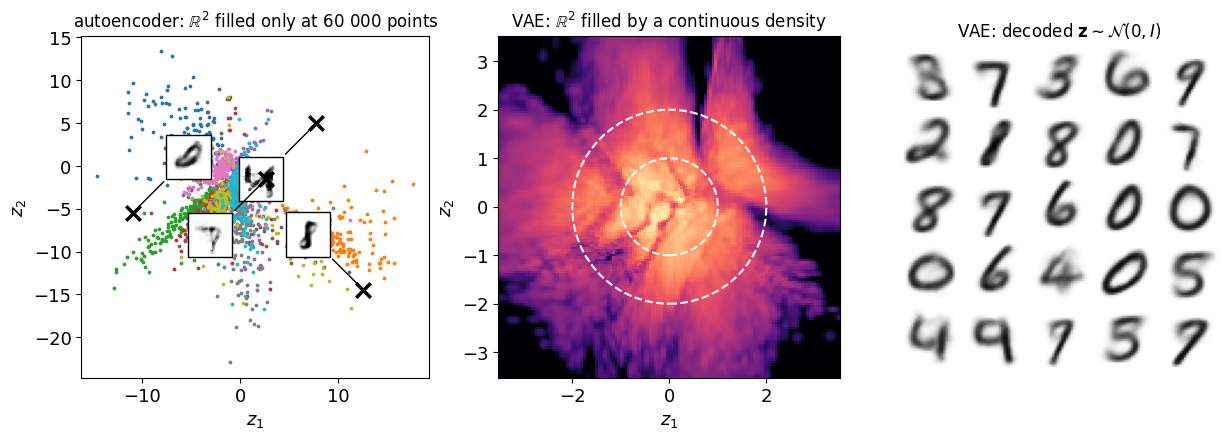

In [19]:
# the autoencoder fills the latent plane at N points, the VAE with a continuous density
from scipy.spatial import cKDTree
from scipy.interpolate import RegularGridInterpolator
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.colors import LogNorm

with torch.no_grad():
    Z_tr = enc_ae(Xtr_t).numpy()                                 # the N training codes of the autoencoder
    Z_te = enc_ae(Xte_t[:2000]).numpy()
    mu_tr, lv_tr = [t.numpy() for t in vae2.encode(Xtr_t)]       # the N clouds of the VAE
N = len(Z_tr); sd_tr = np.exp(0.5 * lv_tr)
rng_l = np.random.default_rng(5)

# four latent points far from every training code of the autoencoder, and what the decoder makes of them
tree_ae = cKDTree(Z_tr)
lo_, hi_ = np.percentile(Z_tr, 3, 0), np.percentile(Z_tr, 97, 0)
cand = rng_l.uniform(lo_, hi_, size=(4000, 2)); dist = tree_ae.query(cand)[0]
empty = []
for j in np.argsort(-dist):
    if all(np.linalg.norm(cand[j] - cand[k]) > 0.25 * np.linalg.norm(hi_ - lo_) for k in empty): empty.append(j)
    if len(empty) == 4: break
z_empty = cand[empty]
with torch.no_grad(): img_empty = dec_ae(torch.tensor(z_empty, dtype=torch.float32)).numpy()

# aggregate posterior of the VAE, q(z) = (1/N) sum_i N(z; mu_i, diag sigma_i^2), on a grid
gq = np.linspace(-3.5, 3.5, 141); GX, GY = np.meshgrid(gq, gq)
P = torch.tensor(np.stack([GX.ravel(), GY.ravel()], 1), dtype=torch.float32)
mu_t, sd_t = torch.tensor(mu_tr), torch.tensor(sd_tr); q = torch.zeros(len(P))
for i in range(0, N, 1000):
    m, s = mu_t[i:i + 1000], sd_t[i:i + 1000]
    e = (((P[:, None, :] - m[None]) / s[None]) ** 2).sum(2)
    q += (torch.exp(-0.5 * e) / (2 * np.pi * s.prod(1))[None]).sum(1)
q = (q / N).reshape(GX.shape).numpy()

# the numbers: distance to the nearest code in units of the code spacing, cloud width, empty prior mass
def gap_ratio(codes, z):
    t = cKDTree(codes); spacing = np.median(t.query(codes, k=2)[0][:, 1])
    return np.median(t.query(z)[0]) / spacing, spacing
z_ae = rng_l.multivariate_normal(Z_tr.mean(0), np.cov(Z_tr.T), 2000)    # a Gaussian fitted to the autoencoder codes
z_vae = rng_l.standard_normal((2000, 2))
r_ae, _ = gap_ratio(Z_tr, z_ae); r_vae, sp_vae = gap_ratio(mu_tr, z_vae)
zz = z_vae[np.all(np.abs(z_vae) < 3.5, 1)]
q_at = RegularGridInterpolator((gq, gq), q.T)(zz)
frac_low = float(np.mean(q_at < 0.1 * np.exp(-0.5 * (zz ** 2).sum(1)) / (2 * np.pi)))
print(f"N = {N} training codes")
print(f"median distance to the nearest code / median code spacing: autoencoder {r_ae:.1f}, VAE {r_vae:.2f}")
print(f"median cloud width sigma of the VAE / median code spacing: {np.median(sd_tr) / sp_vae:.1f}")
print(f"fraction of N(0, I) draws where q(z) < 0.1 N(z; 0, I): {frac_low:.3f}")

with plt.rc_context({"font.size": 13}):
    fig = plt.figure(figsize=(12, 4.5))
    a0 = fig.add_axes([0.04, 0.11, 0.29, 0.76]); a1 = fig.add_axes([0.385, 0.11, 0.29, 0.76]); a2 = fig.add_axes([0.72, 0.11, 0.27, 0.76])
    cm = plt.get_cmap("tab10")
    for k in range(10): a0.scatter(*Z_te[yte[:2000] == k].T, s=3, color=cm(k), rasterized=True)
    a0.scatter(*z_empty.T, s=110, marker="x", color="k", lw=2.5, zorder=4)
    c0 = Z_tr.mean(0)
    for zp, im in zip(z_empty, img_empty):
        off = (-40 * (np.sign(zp[0] - c0[0]) or 1), -40 * (np.sign(zp[1] - c0[1]) or 1))     # inset towards the centre
        a0.add_artist(AnnotationBbox(OffsetImage(im.reshape(28, 28), cmap="gray_r", zoom=1.0), zp, xybox=off, boxcoords="offset points",
                                     arrowprops=dict(arrowstyle="-", color="k", lw=1), pad=0.15))
    a0.set_xlabel("$z_1$"); a0.set_ylabel("$z_2$")
    a0.set_title(f"autoencoder: $\\mathbb{{R}}^2$ filled only at {N:,} points".replace(",", " "), fontsize=12)
    a1.pcolormesh(GX, GY, np.maximum(q, q.max() * 1e-4), norm=LogNorm(vmin=q.max() * 1e-4, vmax=q.max()), cmap="magma", shading="auto", rasterized=True)
    for r_ in (1, 2): a1.add_patch(plt.Circle((0, 0), r_, fill=False, ls="--", color="white", lw=1.5))
    a1.set_aspect("equal"); a1.set_xlabel("$z_1$"); a1.set_ylabel("$z_2$")
    a1.set_title("VAE: $\\mathbb{R}^2$ filled by a continuous density", fontsize=12)
    with torch.no_grad():
        zs = torch.randn(25, 2, generator=torch.Generator().manual_seed(7))
        ims = torch.sigmoid(vae2.decode(zs)).reshape(5, 5, 28, 28).numpy()
    a2.imshow(ims.transpose(0, 2, 1, 3).reshape(140, 140), cmap="gray_r", vmin=0, vmax=1); a2.axis("off")
    a2.set_title("VAE: decoded $\\mathbf{z}\\sim\\mathcal{N}(0,I)$", fontsize=12)
    fig.savefig(f"{RES}/gen_discrete_vs_continuous_latent.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

Random points from a Gaussian fitted to the autoencoder codes lie a median 1.6 code spacings from the nearest training code; draws from the prior of the VAE lie 1.32 spacings away. The decisive number is the width of the VAE clouds, a median of 5.6 code spacings: each cloud covers many neighbouring codes, and the clouds overlap into the continuous density of the middle panel. Only 3.6% of draws from the prior fall where this density is below a tenth of the prior, in the dark wedges, and the 25 decoded draws of the right panel are digits, some of them blurred.

### Reconstruction and generation

Reconstruction and generation use the same decoder on different inputs. Reconstruction encodes a given image and decodes the centre of its cloud, $\operatorname{sigmoid}(G(\boldsymbol\mu(\mathbf x)))$; it measures how much of $\mathbf x$ survives the compression to 16 numbers, and it needs the encoder. Generation decodes a $\mathbf z$ drawn from the prior, with no input image. The figure shows, from top to bottom, eight test digits, their reconstructions, the means decoded from eight random $\mathbf z$, and one Bernoulli draw of every pixel for the same $\mathbf z$.

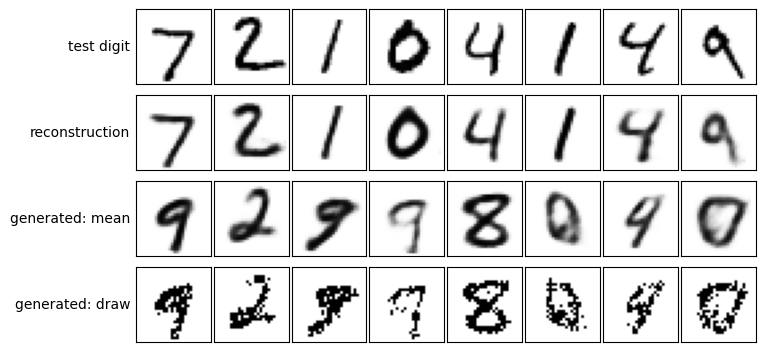

reconstruction error (BCE) per image of these 8 digits: 66.4
fraction of pixels with a mean between 0.1 and 0.9: 0.197


In [20]:
# reconstruction (encode, decode the centre mu) against generation (decode z ~ N(0, I)); mean against Bernoulli draw
gen_ = torch.Generator().manual_seed(20)
with torch.no_grad():
    x8 = Xte_t[:8]
    rec = torch.sigmoid(vae16.decode(vae16.encode(x8)[0]))
    gen_mean = torch.sigmoid(vae16.decode(torch.randn(8, 16, generator=gen_)))
    gen_draw = torch.bernoulli(gen_mean, generator=gen_)
rows = [("test digit", x8), ("reconstruction", rec), ("generated: mean", gen_mean), ("generated: draw", gen_draw)]
fig, axs = plt.subplots(4, 8, figsize=(8, 4.4))
for r, (name, imgs) in enumerate(rows):
    for j in range(8):
        axs[r, j].imshow(imgs[j].reshape(28, 28).numpy(), cmap="gray_r", vmin=0, vmax=1); axs[r, j].set_xticks([]); axs[r, j].set_yticks([])
    axs[r, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=10)
plt.subplots_adjust(wspace=0.04, hspace=0.06); plt.show()
print(f"reconstruction error (BCE) per image of these 8 digits: {F.binary_cross_entropy(rec, x8, reduction='sum').item() / 8:.1f}")
print(f"fraction of pixels with a mean between 0.1 and 0.9: {((gen_mean > 0.1) & (gen_mean < 0.9)).float().mean():.3f}")

The reconstructions keep the identity and most of the shape of the eight test digits, with soft edges; their binary cross-entropy is 66.4 per image. The decoded means of random latent vectors look like digits but are less clean, and some lie between two classes. The decoder output is a probability for every pixel, and 19.7% of the pixels of the generated means lie between 0.1 and 0.9, so a Bernoulli draw of every pixel gives the speckled images of the last row. Showing the mean is the usual convention for VAEs on images; the draw is what the model, read literally as the distribution of equation (31), generates.

### Interpolation

In a latent space without gaps, the straight line between the codes of two images decodes to a continuous sequence of plausible images. We encode a test 2 and a test 7 to the centres $\boldsymbol\mu_a,\boldsymbol\mu_b$ of their clouds and decode
$$\mathbf z(t)=(1-t)\,\boldsymbol\mu_a+t\,\boldsymbol\mu_b,\qquad 0\le t\le 1. \tag{34}$$
The bottom row interpolates the pixels instead,
$$\mathbf x(t)=(1-t)\,\mathbf x_a+t\,\mathbf x_b. \tag{35}$$

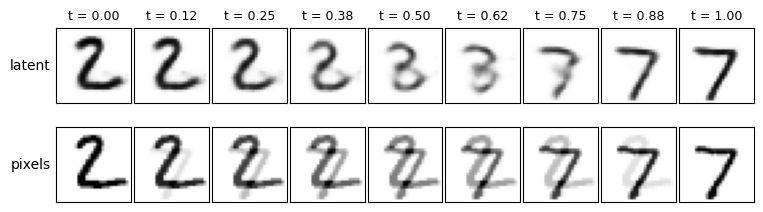

In [21]:
# interpolation between a test 2 and a test 7: in latent space (top) and in pixel space (bottom)
ia, ib = int(np.flatnonzero(yte == 2)[0]), int(np.flatnonzero(yte == 7)[0])
ts = np.linspace(0, 1, 9)
with torch.no_grad():
    ma, mb = vae16.encode(Xte_t[[ia, ib]])[0]
    lat = torch.sigmoid(vae16.decode(torch.stack([(1 - t) * ma + t * mb for t in ts]))).numpy()
pix = np.stack([(1 - t) * Xte[ia] + t * Xte[ib] for t in ts])
fig, axs = plt.subplots(2, 9, figsize=(9, 2.5))
for j, t in enumerate(ts):
    for r, imgs in enumerate((lat, pix)):
        axs[r, j].imshow(imgs[j].reshape(28, 28), cmap="gray_r", vmin=0, vmax=1); axs[r, j].set_xticks([]); axs[r, j].set_yticks([])
    axs[0, j].set_title(f"t = {t:.2f}", fontsize=9)
for r, name in enumerate(("latent", "pixels")): axs[r, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=10)
plt.subplots_adjust(wspace=0.04, hspace=0.06); plt.show()

In latent space the 2 turns into a 7 through images that each look like handwriting, passing through a shape resembling a 3 near the middle of the path. In pixel space the two images are blended: every intermediate image shows both digits superimposed, which no writer produces. The latent path stays on the set of digit-like images, the pixel path leaves it.

### Latent coordinates

Each latent coordinate $z_k$ is a direction in latent space, and moving along it changes the decoded image. The grid of the two-dimensional VAE is such a scan in both directions at once: along $z_1$ and along $z_2$ the digit changes its identity, slant and width together. For the VAE with 16 latent dimensions we move one coordinate at a time from $-3$ to $3$, with the others at 0. The rows are sorted by the KL divergence of the coordinate, averaged over the test digits, which measures how much information about the image the coordinate carries.

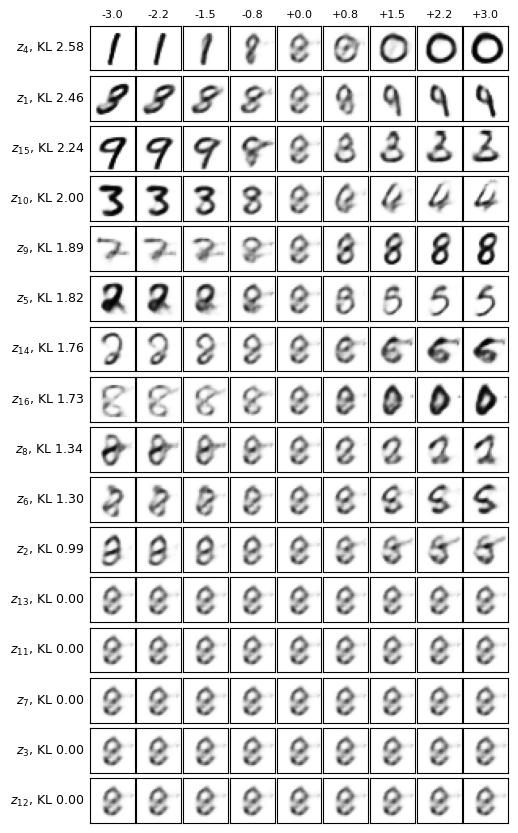

KL per coordinate, largest first: [2.58 2.46 2.24 2.   1.89 1.82 1.76 1.73 1.34 1.3  0.99 0.   0.   0.
 0.   0.  ]  sum: 20.1


In [22]:
# one latent coordinate at a time: z_k from -3 to 3, all other coordinates 0; rows sorted by the KL of z_k
with torch.no_grad():
    mu_t, lv_t = vae16.encode(Xte_t)
kl_k = (0.5 * (mu_t ** 2 + lv_t.exp() - lv_t - 1)).mean(0).numpy()      # KL divergence per coordinate, mean over test digits
order = np.argsort(-kl_k)
vals = np.linspace(-3, 3, 9)
z = torch.zeros(16 * len(vals), 16)
for r, k in enumerate(order): z[r * len(vals):(r + 1) * len(vals), k] = torch.tensor(vals, dtype=torch.float32)
with torch.no_grad(): imgs = torch.sigmoid(vae16.decode(z)).numpy()
fig, axs = plt.subplots(16, len(vals), figsize=(5.4, 10.4))
for r, k in enumerate(order):
    for j in range(len(vals)):
        a = axs[r, j]; a.imshow(imgs[r * len(vals) + j].reshape(28, 28), cmap="gray_r", vmin=0, vmax=1); a.set_xticks([]); a.set_yticks([])
    axs[r, 0].set_ylabel(f"$z_{{{k + 1}}}$, KL {kl_k[k]:.2f}", rotation=0, ha="right", va="center", fontsize=9)
for j, v in enumerate(vals): axs[0, j].set_title(f"{v:+.1f}", fontsize=8)
plt.subplots_adjust(wspace=0.04, hspace=0.04); plt.show()
print("KL per coordinate, largest first:", kl_k[order].round(2), " sum:", round(float(kl_k.sum()), 1))

Eleven of the sixteen coordinates carry information, with an average KL divergence between 0.99 and 2.58 nats, and five are unused, with KL 0.00: moving them does not change the decoded image. The sum, 20.1 nats on the test digits, is close to the KL term of 19.6 nats measured at the end of training. The informative coordinates move between digit identities rather than changing one property: the first row turns a 1 into a 0 through an 8, the second a slanted 8 into a 9, the third a 9 into a 3.

Nothing in the VAE loss asks a coordinate to correspond to one property of the digit. The prior $\mathcal N(0,I)$ looks the same in every rotated coordinate system and does not single out the axes; in general one coordinate changes several properties at once, and one property, such as the slant, is spread over several coordinates. A representation with one coordinate per property is called *disentangled*. The β-VAE ([Higgins et al. 2017](https://openreview.net/forum?id=Sy2fzU9gl)) pursues it by weighting the KL term with a factor $\beta$ larger than 1; it is the subject of the notebook `notebook_2026-10-27-beta_vae.ipynb`.

## Conditional VAE

Often we want to say *what* to generate. A conditional VAE receives a known label $\mathbf c$ as an extra input of both networks, $E(\mathbf x,\mathbf c)$ and $G(\mathbf z,\mathbf c)$, while the loss stays unchanged. Since $\mathbf c$ already tells the decoder which digit to draw, the latent vector $\mathbf z$ only needs to carry what $\mathbf c$ does not say: the **style**, such as slant, thickness and size.

Here $\mathbf c$ is the one-hot vector of the digit. Generation samples
$$p_\theta(\mathbf x|\mathbf c)=\int p_\theta(\mathbf x|\mathbf z,\mathbf c)\,p(\mathbf z)\,d\mathbf z : \tag{36}$$
the condition is fixed, $\mathbf z$ is drawn from $\mathcal N(0,I)$, and the decoder is applied to $[\mathbf z,\mathbf c]$. Fixing $\mathbf c$ chooses *what* is drawn, drawing $\mathbf z$ chooses *how*. In the figure each row is one digit and each column one random $\mathbf z$, the **same** in every row. Read down a column, one $\mathbf z$ with ten different $\mathbf c$ should keep the style; read along a row, eight $\mathbf z$ for one $\mathbf c$ give the variety within the class.

loss per image 97.6 = reconstruction 83.4 + KL 14.2


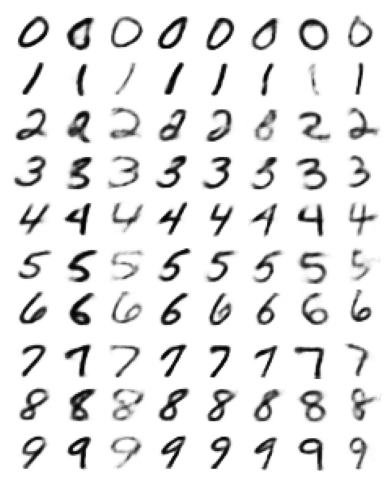

In [23]:
rng = seed(2)
Ctr = F.one_hot(torch.tensor(ytr.astype(np.int64)), 10).float()
cvae = VAE(d=8, cond=10); hc = train_vae(cvae, Xtr_t, Ctr, epochs=20); cvae.eval()
print(f"loss per image {hc[-1, 0]:.1f} = reconstruction {hc[-1, 1]:.1f} + KL {hc[-1, 2]:.1f}")
torch.manual_seed(11); zc = torch.randn(8, 8)
rows = []
with torch.no_grad():
    for dgt in range(10):
        c = F.one_hot(torch.full((8,), dgt), 10).float()
        rows.append(torch.sigmoid(cvae.decode(zc, c)).numpy())
show_grid(np.concatenate(rows), 10, 8, f"{OUT}/gen_cvae_mnist.png", size=0.6)

### Conditional VAE architecture

The conditional VAE has the layers of the VAE above, and the 10 numbers of the one-hot label $\mathbf c$ (green) are appended to the input of the encoder and to the input of the decoder. The first encoder layer therefore receives $784+10$ numbers, and the first decoder layer $8+10$ for the eight latent dimensions used here. The label enters the decoder from outside; it is not computed from $\boldsymbol\mu$ and $\log\boldsymbol\sigma^2$, so the drawing shows no edges into it. The figure is also saved as `arch_cvae.png` for the slides. The `torchinfo` table needs both inputs of the model, the image and the label, which we pass as a list. Compared with the VAE, only the first layer of the encoder and the first layer of the decoder gain parameters, $10\times512$ and $10\times256$ weights for the label.

columns read from the model: [[784, 10], 512, 256, [8, 8], [8, 10], 256, 512, 784]


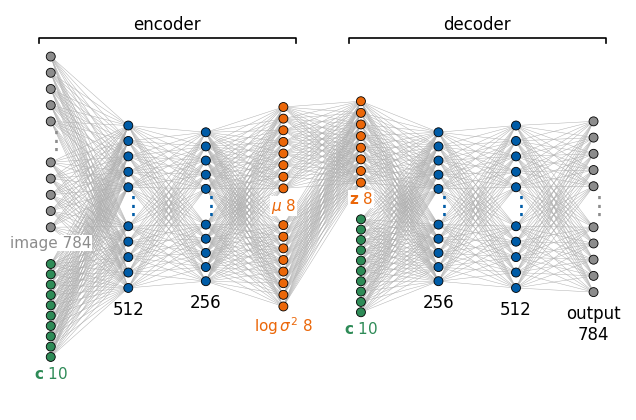

Layer (type:depth-idx)                   Output Shape              Param #
VAE                                      [1, 784]                  --
├─Sequential: 1-1                        [1, 256]                  --
│    └─Linear: 2-1                       [1, 512]                  407,040
│    └─ReLU: 2-2                         [1, 512]                  --
│    └─Linear: 2-3                       [1, 256]                  131,328
│    └─ReLU: 2-4                         [1, 256]                  --
├─Linear: 1-2                            [1, 8]                    2,056
├─Linear: 1-3                            [1, 8]                    2,056
├─Sequential: 1-4                        [1, 784]                  --
│    └─Linear: 2-5                       [1, 256]                  4,864
│    └─ReLU: 2-6                         [1, 256]                  --
│    └─Linear: 2-7                       [1, 512]                  131,584
│    └─ReLU: 2-8                         [1, 512]            

In [24]:
# conditional VAE: the one-hot digit c is concatenated to the inputs of encoder and decoder
with torch.random.fork_rng():
    cvae_d8 = VAE(d=8, cond=10)                                  # the architecture trained above
    table = summary(cvae_d8, input_data=[torch.zeros(1, 784), torch.zeros(1, 10)], col_names=("output_size", "num_params"), verbose=0)
cols = vae_columns(cvae_d8)
print("columns read from the model:", cols)
assert dense_params(cols, sampled={len(cols) - 4}) == table.total_params

fig, ax = plt.subplots(figsize=(12, 5.2))                      # slide size: labels of 12 pt at full slide width
draw_network(cols, **vae_style(cols), x_gap=1.9, fontsize=12, ax=ax)
fig.savefig(f"{OUT}/arch_cvae.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print(table)

### Classifier test of the generated digits

Looking at the pictures is not enough to decide whether the generated digits really show the digit we asked for. We therefore train a small classifier on the **real** MNIST training images (a dense network $784\to256\to10$, cross-entropy loss, 3 epochs), check its accuracy on the real test images, and then let it label 200 generated images for each requested digit. The fraction labelled as the requested digit measures how well the conditional VAE respects its condition.

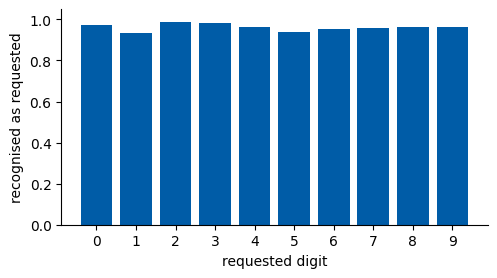

classifier accuracy on real test digits: 0.971
fraction of generated digits recognised as the requested digit: [0.98 0.94 0.98 0.98 0.96 0.94 0.96 0.96 0.96 0.96]  mean 0.963


In [25]:
rng = seed(4)
clf = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 10))
optc = torch.optim.Adam(clf.parameters(), 1e-3)
for ep in range(3):
    perm = torch.randperm(len(Xtr_t))
    for i in range(0, len(perm), 128):
        j = perm[i:i + 128]; loss = F.cross_entropy(clf(Xtr_t[j]), torch.tensor(ytr[j.numpy()].astype(np.int64)))
        optc.zero_grad(); loss.backward(); optc.step()
clf.eval()
with torch.no_grad():
    acc = (clf(Xte_t).argmax(1).numpy() == yte).mean()
    agree_cvae = []
    for dgt in range(10):
        cc = F.one_hot(torch.full((200,), dgt), 10).float()
        agree_cvae.append(float((clf(torch.sigmoid(cvae.decode(torch.randn(200, 8), cc))).argmax(1).numpy() == dgt).mean()))
nums["clf_acc"] = float(acc); nums["cvae_agreement"] = [round(a, 3) for a in agree_cvae]
fig, ax = plt.subplots(figsize=(5.5, 2.8))
ax.bar(range(10), agree_cvae, color=blue); ax.set_ylim(0, 1.05); ax.set_xticks(range(10))
ax.set_xlabel("requested digit"); ax.set_ylabel("recognised as requested"); clean(ax)
plt.savefig(f"{OUT}/gen_cvae_mnist_check.png", dpi=170, bbox_inches="tight"); plt.show()
print(f"classifier accuracy on real test digits: {acc:.3f}")
print("fraction of generated digits recognised as the requested digit:", np.round(agree_cvae, 2), " mean", round(float(np.mean(agree_cvae)), 3))

The classifier reaches an accuracy of 0.971 on real test digits, and it recognises on average 96.3% of the generated digits as the digit that was requested, between 94% and 98% for each digit. The conditional VAE therefore respects its condition about as well as the classifier can judge.

As an exercise, keep $\mathbf c$ fixed and move along one latent coordinate, $z_1$ from $-3$ to $3$, with the others at 0. Which property of the digit changes?

## Blood-cell images of a chosen type

The conditional VAE applies equally to the blood-cell images of BloodMNIST (Lecture 4).

### BloodMNIST data

BloodMNIST belongs to the MedMNIST collection ([Yang et al. 2023](https://doi.org/10.1038/s41597-022-01721-8)). It is built from 17 092 microscope images of individual normal blood cells of healthy donors, taken at the Hospital Clinic of Barcelona ([Acevedo et al. 2020](https://doi.org/10.1016/j.dib.2020.105474)) and reduced to $28\times28$ pixels. One sample is the RGB (red, green, blue) image of one cell, three values from 0 to 255 per pixel, divided by 255 here. Its label is one of eight cell types: basophil, eosinophil, erythroblast, immature granulocyte, lymphocyte, monocyte, neutrophil and platelet. The images are split into 11 959 for training, 1712 for validation (not used here) and 3421 for testing, and the classes are unbalanced, from 849 lymphocytes to 2330 neutrophils in the training set. The file is taken from the Lecture 4 folder, or downloaded from Zenodo.

### Convolutional conditional VAE

The condition $\mathbf c$ is the one-hot cell type. The images have three colour channels, so encoder and decoder are convolutional, like the convolutional neural networks (CNNs) of Lecture 4. To check whether the generated cells look like their type, we train a small CNN classifier on the real images, generate 100 cells of each type, and count how many the classifier assigns to the requested type. Both networks are trained on the BloodMNIST training images, and generated cells are shown next to real cells of each type.

training images: (11959, 3, 28, 28)  test images: (3421, 3, 28, 28)


trained in 110 s; last batch: reconstruction 1161.0 + KL 14.5


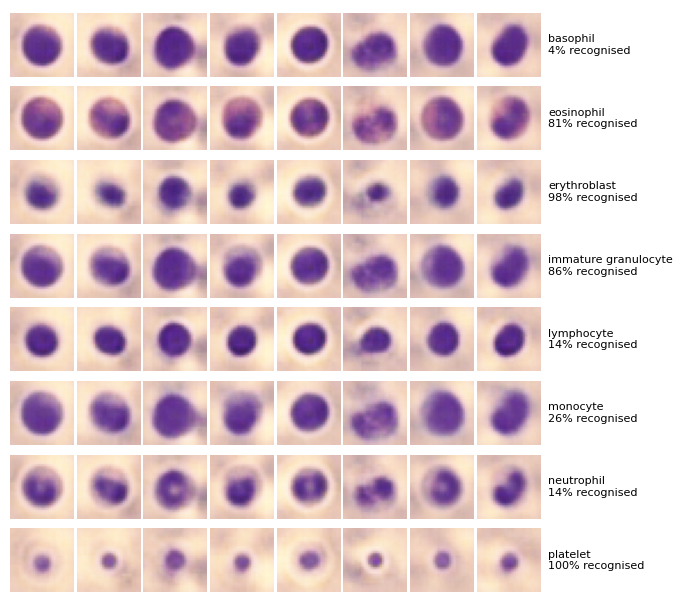

classifier test accuracy 0.838
{'basophil': 0.04, 'eosinophil': 0.81, 'erythroblast': 0.98, 'immature granulocyte': 0.86, 'lymphocyte': 0.14, 'monocyte': 0.26, 'neutrophil': 0.14, 'platelet': 1.0}


In [26]:
import urllib.request
bpath = "data/bloodmnist.npz"
if not os.path.exists(bpath):
    bpath = "data/bloodmnist.npz"
    if not os.path.exists(bpath):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve("https://zenodo.org/records/10519652/files/bloodmnist.npz?download=1", bpath)
bd = np.load(bpath)
names = ["basophil", "eosinophil", "erythroblast", "immature granulocyte", "lymphocyte", "monocyte", "neutrophil", "platelet"]
to_t = lambda a: torch.tensor(a.astype(np.float32) / 255).permute(0, 3, 1, 2)      # (n, 3, 28, 28)
Btr, Bte = to_t(bd["train_images"]), to_t(bd["test_images"])
bytr, byte = bd["train_labels"].ravel(), bd["test_labels"].ravel()
Cb = F.one_hot(torch.tensor(bytr.astype(np.int64)), 8).float()
print("training images:", tuple(Btr.shape), " test images:", tuple(Bte.shape))

class ConvCVAE(nn.Module):
    def __init__(self, d=16, cond=8):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(3 + cond, 32, 3, 2, 1), nn.ReLU(), nn.Conv2d(32, 64, 3, 2, 1), nn.ReLU(), nn.Flatten())
        self.mu, self.logvar = nn.Linear(64 * 7 * 7, d), nn.Linear(64 * 7 * 7, d)
        self.fc = nn.Linear(d + cond, 64 * 7 * 7)
        self.dec = nn.Sequential(nn.ReLU(), nn.Unflatten(1, (64, 7, 7)), nn.ConvTranspose2d(64, 32, 3, 2, 1, output_padding=1), nn.ReLU(),
                                 nn.ConvTranspose2d(32, 3, 3, 2, 1, output_padding=1))
        self.cond = cond
    def encode(self, x, c):
        cmap_ = c[:, :, None, None].expand(-1, -1, x.shape[2], x.shape[3])        # the condition as extra input channels
        h = self.enc(torch.cat([x, cmap_], 1)); return self.mu(h), self.logvar(h)
    def decode(self, z, c): return self.dec(self.fc(torch.cat([z, c], 1)))       # logits of the pixels
    def forward(self, x, c):
        mu, logvar = self.encode(x, c); z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return self.decode(z, c), mu, logvar

rng = seed(7); t0 = time.time()
bcvae = ConvCVAE(); optb = torch.optim.Adam(bcvae.parameters(), 1e-3)
for ep in range(30):
    perm = torch.randperm(len(Btr))
    for i in range(0, len(perm), 128):
        j = perm[i:i + 128]; logits, mu, logvar = bcvae(Btr[j], Cb[j])
        loss, rec, kl = vae_loss(logits.flatten(1), Btr[j].flatten(1), mu, logvar)
        optb.zero_grad(); loss.backward(); optb.step()
bcvae.eval(); print(f"trained in {time.time() - t0:.0f} s; last batch: reconstruction {rec.item():.1f} + KL {kl.item():.1f}")

# a classifier of the real cells, for the check
rng = seed(8)
clfb = nn.Sequential(nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                     nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 8))
optk = torch.optim.Adam(clfb.parameters(), 1e-3); ybt = torch.tensor(bytr.astype(np.int64))
for ep in range(8):
    perm = torch.randperm(len(Btr))
    for i in range(0, len(perm), 128):
        j = perm[i:i + 128]; loss = F.cross_entropy(clfb(Btr[j]), ybt[j]); optk.zero_grad(); loss.backward(); optk.step()
clfb.eval()
with torch.no_grad(): accb = (clfb(Bte).argmax(1).numpy() == byte).mean()
nums["blood_clf_test_acc"] = float(accb)

torch.manual_seed(13)
with torch.no_grad():
    zb = torch.randn(8, 16); rows = []
    for c in range(8):
        rows.append(torch.sigmoid(bcvae.decode(zb, F.one_hot(torch.full((8,), c), 8).float())).permute(0, 2, 3, 1).numpy())
    agree = []
    for c in range(8):
        g = torch.sigmoid(bcvae.decode(torch.randn(100, 16), F.one_hot(torch.full((100,), c), 8).float()))
        agree.append(float((clfb(g).argmax(1).numpy() == c).mean()))
nums["blood_cvae_class_agreement"] = [round(a, 2) for a in agree]
fig, axs = plt.subplots(8, 9, figsize=(8.2, 7.6), gridspec_kw=dict(width_ratios=[1] * 8 + [1.6]))
for c in range(8):
    for j in range(8):
        axs[c, j].imshow(rows[c][j]); axs[c, j].axis("off")
    axs[c, 8].axis("off"); axs[c, 8].text(0.05, 0.5, f"{names[c]}\n{100 * agree[c]:.0f}% recognised", va="center", fontsize=8)
plt.subplots_adjust(wspace=0.04, hspace=0.06); plt.savefig(f"{OUT}/gen_cvae_blood.png", dpi=170, bbox_inches="tight"); plt.show()
print(f"classifier test accuracy {accb:.3f}"); print({n: a for n, a in zip(names, agree)})

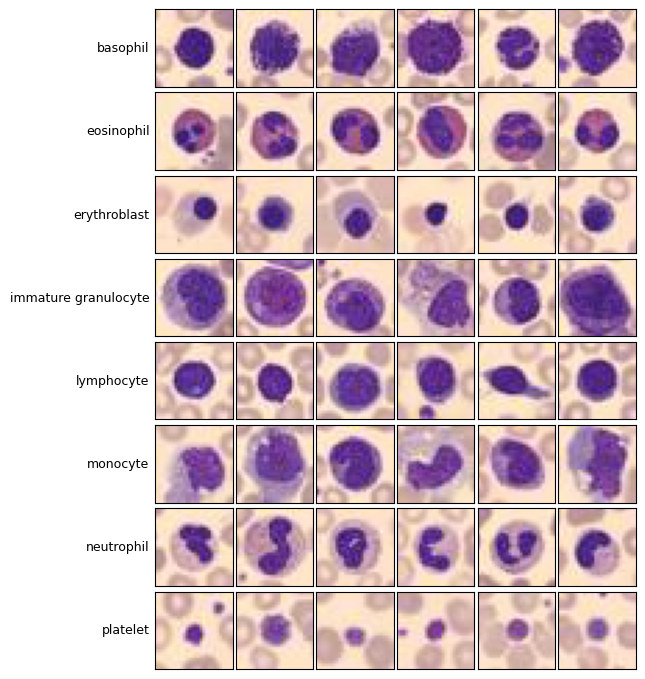

training / validation / test images: 11959 1712 3421


In [27]:
# six training images of every cell type
ylab = np.asarray(bytr)
fig, axs = plt.subplots(8, 6, figsize=(6.2, 8.6))
for k, name in enumerate(names):
    for j, i in enumerate(np.flatnonzero(ylab == k)[:6]):
        axs[k, j].imshow(np.asarray(Btr[i]).transpose(1, 2, 0)); axs[k, j].set_xticks([]); axs[k, j].set_yticks([])
    axs[k, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
plt.subplots_adjust(wspace=0.04, hspace=0.04); plt.show()
print("training / validation / test images:", len(bd["train_labels"]), len(bd["val_labels"]), len(bd["test_labels"]))

In the figure of generated cells, each row is one requested cell type and each column one random $\mathbf z$, the same in every row; the figure after it shows real training cells for comparison. The percentage is the fraction of the 100 generated cells of that type that the classifier, which reaches a test accuracy of 0.838 on real cells, assigns to the requested type. The results are very uneven: platelets (100%) and erythroblasts (98%) are recognised almost always, eosinophils (81%) and immature granulocytes (86%) mostly, whereas basophils (4%), lymphocytes (14%), neutrophils (14%) and monocytes (26%) are mostly not.

As an exercise, generate cells of one type with several values of a single latent coordinate. What changes in the image?

## Boltzmann distribution of the 2D Ising model

For spins we **know** the true distribution (Lecture 4),
$$p(\mathbf s\,|\,T)=\frac{e^{-H(\mathbf s)/T}}{Z}, \tag{37}$$
and Metropolis Monte Carlo samples it exactly. This makes the Ising model a good test of whether a network can learn a distribution from samples alone.

### Ising data

The data are spin configurations of the Ising model ([Ising 1925](https://doi.org/10.1007/BF02980577)) on a $20\times20$ square lattice with periodic boundaries,
$$H(\mathbf s)=-J\sum_{\langle ij\rangle}s_is_j, \tag{38}$$
with coupling $J$ of 1 and the sum over nearest neighbours, sampled with the Metropolis algorithm ([Metropolis et al. 1953](https://doi.org/10.1063/1.1699114)). This is the data set of Lecture 4, regenerated here if missing. One sample is a configuration of 400 spins, each $+1$ or $-1$, and its label is the temperature $T$ at which it was drawn: 51 temperatures from 1.0 to 3.5 in steps of 0.05, with 200 configurations each, 10 200 in total. On the infinite lattice the order is lost at the critical temperature
$$T_c=\frac{2}{\ln\big(1+\sqrt2\big)}\approx2.269 \tag{39}$$
 ([Onsager 1944](https://doi.org/10.1103/PhysRev.65.117)): below it most spins point the same way, above it the magnetisation vanishes. Example configurations at several temperatures illustrate the data.

### Conditional VAE on spin configurations

We train a conditional VAE with the temperature as condition $\mathbf c$, rescaled to about $[-1.7,1.7]$, on all 10 200 configurations. Spins are mapped to pixels $(s_i+1)/2$, which are 0 or 1, so the same BCE loss applies. To generate at a chosen $T$ we draw $\mathbf z$ from $\mathcal N(0,I)$, decode, and draw each spin up with the decoded probability. The generated configurations are compared with Monte Carlo through two observables at each temperature: the magnetisation $\langle|M|\rangle$ and the energy per spin.

Monte Carlo data: (51, 200, 20, 20) temperatures 1.0 ... 3.5


loss per configuration 139.2 = reconstruction 132.8 + KL 6.3


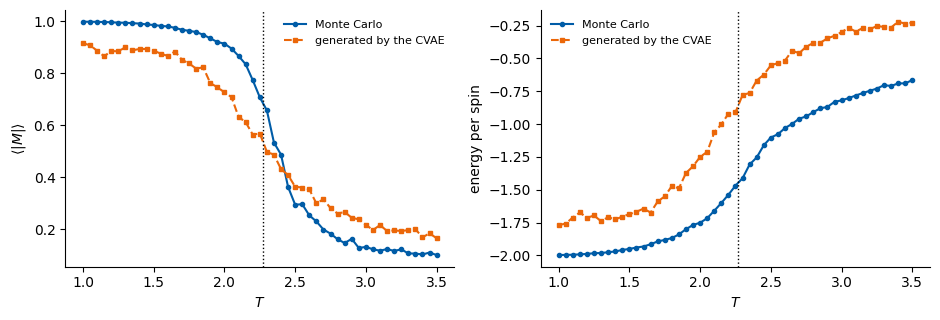

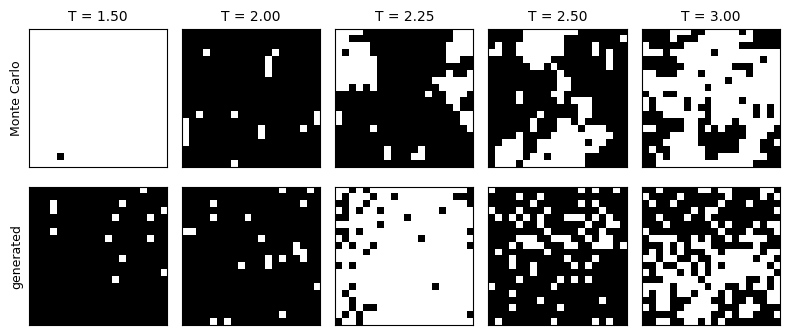

{'ising_cvae_M_maxdiff': 0.234, 'ising_cvae_E_maxdiff': 0.634, 'ising_cvae_E_maxdiff_T': 2.3}


In [28]:
path = "data/ising_Nx20_Ny20.npz"
if not os.path.exists(path):
    path = "data/ising_Nx20_Ny20.npz"
    if not os.path.exists(path):                              # regenerate (checkerboard Metropolis, about a minute)
        r = np.random.default_rng(0); L = 20; Ts = np.round(np.arange(1.0, 3.5 + 1e-9, 0.05), 2)
        y_, x_ = np.indices((L, L)); masks = ((x_ + y_) % 2 == 0, (x_ + y_) % 2 == 1)
        beta = (1 / Ts.astype(np.float32))[None, :, None, None]; s = np.ones((20, len(Ts), L, L), np.float32)
        def sweep(s):
            for m in masks:
                nb = np.roll(s, 1, -1) + np.roll(s, -1, -1) + np.roll(s, 1, -2) + np.roll(s, -1, -2)
                s[...] = np.where(m & (r.random(s.shape, dtype=np.float32) < np.exp(-beta * 2 * s * nb)), -s, s)
        for _ in range(1200): sweep(s)
        st = []
        for k in range(10):
            for _ in range(20): sweep(s)
            st.append(s.copy())
        cf = np.stack(st).transpose(2, 0, 1, 3, 4).reshape(len(Ts), 200, L, L).astype(np.int8)
        os.makedirs("data", exist_ok=True); np.savez_compressed(path, configs=cf, T=Ts)
d = np.load(path); cfg, Ts = d["configs"].astype(np.float32), d["T"]
L = cfg.shape[-1]; N = L * L
print("Monte Carlo data:", cfg.shape, "temperatures", Ts[0], "...", Ts[-1])
Xs = torch.tensor(((cfg + 1) / 2).reshape(-1, N))
Tn = lambda T: (np.asarray(T, np.float32) - 2.25) / 0.75          # the condition: T, rescaled to about [-1.7, 1.7]
Cs = torch.tensor(np.repeat(Tn(Ts), cfg.shape[1]))[:, None]

rng = seed(6)
ivae = VAE(D=N, d=8, cond=1, hidden=(256, 128)); hi_ = train_vae(ivae, Xs, Cs, epochs=60); ivae.eval()
print(f"loss per configuration {hi_[-1, 0]:.1f} = reconstruction {hi_[-1, 1]:.1f} + KL {hi_[-1, 2]:.1f}")

def energy(s):        # energy per spin, J = 1, periodic boundaries; s: (..., L, L) with values +-1
    return -(s * (np.roll(s, 1, -1) + np.roll(s, 1, -2))).mean((-1, -2))
gen_rng = torch.Generator().manual_seed(12)
with torch.no_grad():
    z = torch.randn(len(Ts) * 200, 8, generator=gen_rng)
    prob = torch.sigmoid(ivae.decode(z, Cs))
    gen = (torch.bernoulli(prob, generator=gen_rng) * 2 - 1).numpy().reshape(len(Ts), 200, L, L)
M_mc, M_gen = np.abs(cfg.mean((-1, -2))).mean(1), np.abs(gen.mean((-1, -2))).mean(1)
E_mc, E_gen = energy(cfg).mean(1), energy(gen).mean(1)
nums["ising_cvae_M_maxdiff"] = float(np.abs(M_mc - M_gen).max())
nums["ising_cvae_E_maxdiff"] = float(np.abs(E_mc - E_gen).max())
nums["ising_cvae_E_maxdiff_T"] = float(Ts[np.argmax(np.abs(E_mc - E_gen))])

fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.3))
axs[0].plot(Ts, M_mc, "o-", ms=3, color=blue, label="Monte Carlo"); axs[0].plot(Ts, M_gen, "s--", ms=3, color=orange, label="generated by the CVAE")
axs[1].plot(Ts, E_mc, "o-", ms=3, color=blue, label="Monte Carlo"); axs[1].plot(Ts, E_gen, "s--", ms=3, color=orange, label="generated by the CVAE")
axs[0].set_ylabel(r"$\langle |M| \rangle$"); axs[1].set_ylabel("energy per spin")
TC = 2 / np.log(1 + np.sqrt(2))
for a in axs: a.axvline(TC, color="k", ls=":", lw=1); a.set_xlabel("$T$"); a.legend(frameon=False, fontsize=8); clean(a)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_ising_cvae_observables.png", dpi=170, bbox_inches="tight"); plt.show()

T_show = [1.5, 2.0, 2.25, 2.5, 3.0]
fig, axs = plt.subplots(2, len(T_show), figsize=(8, 3.6))
for k, T in enumerate(T_show):
    i = int(np.argmin(np.abs(Ts - T)))
    for r_, src in enumerate([cfg[i, 0], gen[i, 0]]):
        axs[r_, k].imshow(src, cmap="gray", vmin=-1, vmax=1, interpolation="nearest"); axs[r_, k].set_xticks([]); axs[r_, k].set_yticks([])
    axs[0, k].set_title(f"T = {Ts[i]:.2f}", fontsize=10)
axs[0, 0].set_ylabel("Monte Carlo", fontsize=9); axs[1, 0].set_ylabel("generated", fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT}/gen_ising_cvae_samples.png", dpi=170, bbox_inches="tight"); plt.show()
print({k: round(nums[k], 3) for k in ["ising_cvae_M_maxdiff", "ising_cvae_E_maxdiff", "ising_cvae_E_maxdiff_T"]})

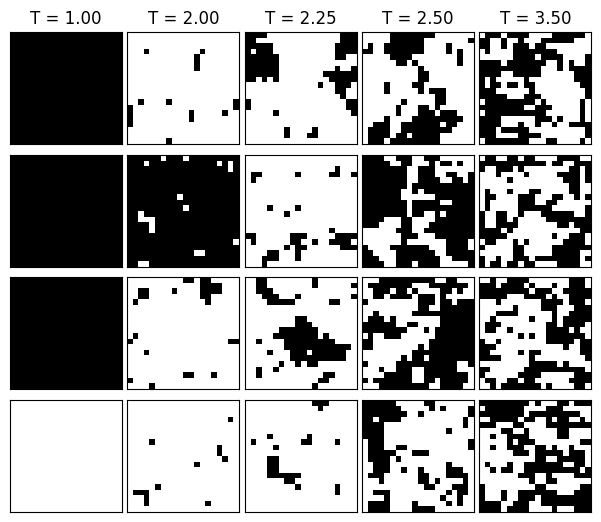

configurations: 10200  spins per configuration: 400


In [29]:
# four Monte Carlo configurations at each of five temperatures (black: s = +1, white: s = -1)
show_T = [1.0, 2.0, 2.25, 2.5, 3.5]
fig, axs = plt.subplots(4, 5, figsize=(7.5, 6.3))
for j, T in enumerate(show_T):
    k = int(np.argmin(np.abs(Ts - T)))
    for r in range(4):
        axs[r, j].imshow(cfg[k, r], cmap="gray_r", vmin=-1, vmax=1); axs[r, j].set_xticks([]); axs[r, j].set_yticks([])
    axs[0, j].set_title(f"T = {Ts[k]:.2f}")
plt.subplots_adjust(wspace=0.05, hspace=0.05); plt.show()
print("configurations:", cfg.shape[0] * cfg.shape[1], " spins per configuration:", N)

The last figure shows Monte Carlo configurations of the training data. At temperature 1 almost all spins are aligned, all up or all down, since $H$ does not change when all spins are flipped; near $T_c$ domains of all sizes appear; at 3.5 neighbouring spins are only weakly correlated.

The comparison rests on the curves, not only on the pictures. The magnetisation tells whether the model learned the **global** order at each temperature; the energy counts aligned **neighbours**, i.e. the local correlations. The largest deviation from Monte Carlo is 0.234 in the magnetisation and 0.634 in the energy per spin, the latter at temperature 2.3, close to the critical temperature. The spins are drawn independently once the decoder has given their probabilities, so any correlation between neighbours must come through the latent vector $\mathbf z$; where the energy of the generated configurations deviates from Monte Carlo, the model has not captured those correlations.

As an exercise, generate at temperature 2.27, a value between two of the training temperatures. Do the generated configurations interpolate sensibly? Increase the latent dimension $d$: does the energy improve?

### Parameter counts

The table collects the number of parameters of every network of this notebook, counted by `torchinfo` on freshly built models with the architectures used above, and the layer tables with the output shape and the parameters of each layer follow it. All parameters are trainable, so for every network the trainable count equals the total.

In [30]:
# torchinfo summary of every network of this notebook, built fresh with the architectures used above
from torchinfo import summary
with torch.random.fork_rng():                                    # building the models does not change later random numbers
    models = [   # name, model, example input, expected number of parameters
        ("autoencoder, d = 2", nn.Sequential(mlp([784, 256, 64, 2]), mlp([2, 64, 256, 784], nn.Sigmoid())), [torch.zeros(1, 784)], None),
        ("VAE, d = 2", VAE(d=2), [torch.zeros(1, 784)], 1_068_820),
        ("VAE, d = 16", VAE(d=16), [torch.zeros(1, 784)], 1_079_600),
        ("conditional VAE, d = 8, c: 10", VAE(d=8, cond=10), [torch.zeros(1, 784), torch.zeros(1, 10)], 1_081_120),
        ("MNIST classifier", nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 10)), [torch.zeros(1, 784)], None),
        ("convolutional conditional VAE, BloodMNIST", ConvCVAE(), [torch.zeros(1, 3, 28, 28), torch.zeros(1, 8)], 219_811),
        ("BloodMNIST classifier", nn.Sequential(nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
                                                nn.MaxPool2d(2), nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 8)),
         [torch.zeros(1, 3, 28, 28)], None),
        ("Ising conditional VAE", VAE(D=400, d=8, cond=1, hidden=(256, 128)), [torch.zeros(1, 400), torch.zeros(1, 1)], 274_976),
    ]
    tables = {name: summary(m, input_data=x, col_names=("output_size", "num_params"), depth=4, verbose=0) for name, m, x, _ in models}

print(f"{'network':45s}{'parameters':>12s}")
for name, m, x, expected in models:
    total = tables[name].total_params
    print(f"{name:45s}{total:>12,}")
    assert tables[name].trainable_params == total
    if expected is not None: assert total == expected, (name, total, expected)
for name, *_ in models:
    print(f"\n{name}"); print(tables[name])

network                                        parameters
autoencoder, d = 2                                435,858
VAE, d = 2                                      1,068,820
VAE, d = 16                                     1,079,600
conditional VAE, d = 8, c: 10                   1,081,120
MNIST classifier                                  203,530
convolutional conditional VAE, BloodMNIST         219,811
BloodMNIST classifier                             421,960
Ising conditional VAE                             274,976

autoencoder, d = 2
Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [1, 784]                  --
├─Sequential: 1-1                        [1, 2]                    --
│    └─Linear: 2-1                       [1, 256]                  200,960
│    └─ReLU: 2-2                         [1, 256]                  --
│    └─Linear: 2-3                       [1, 64]                   16,448
│    └─ReLU: 2-4        

The numbers quoted on the slides are saved to `results/numbers_l6.json`.

In [31]:
json.dump(nums, open(f"{RES}/numbers_l6.json", "w"), indent=1)
print(json.dumps(nums, indent=1))

{
 "gauss_P_within_1sigma": 0.6826894921370859,
 "gauss_peak_sigma02": 1.9947114020071635,
 "mix_mean_estimates": {
  "10": -1.142,
  "100": -0.591,
  "10000": -0.282
 },
 "post_mean": 0.3603117099594829,
 "post_std": 0.24452919880531934,
 "kl_mu_min": -0.25,
 "kl_ml_mean": -0.21149227291354722,
 "kl_ml_std": 1.9291983378841506,
 "kl_p_qstar": 0.26199624527381676,
 "kl_qstar_p": 0.4540578229425971,
 "coin_p7_given_half": 0.1171875,
 "coin_L_at_07": 0.2668279319999998,
 "coin_L_integral": 0.09090909094815097,
 "mle_loglik_1": -4.61345417507708,
 "mle_loglik_3": -3.626732964448672,
 "vae16_loss": 99.90340289713542,
 "vae16_rec": 80.27467460530599,
 "vae16_kl": 19.628728348795573,
 "vae_nn_dist_new": 4.72645378112793,
 "vae_nn_dist_test": 4.0293474197387695,
 "clf_acc": 0.9707,
 "cvae_agreement": [
  0.975,
  0.935,
  0.985,
  0.98,
  0.965,
  0.94,
  0.955,
  0.96,
  0.965,
  0.965
 ],
 "blood_clf_test_acc": 0.8380590470622625,
 "blood_cvae_class_agreement": [
  0.04,
  0.81,
  0.98,
  0